##🥡 **Set form start**

In [5]:
MODEL_ARCHITECTURE = 'CNN_RNN' # 'CNN', 'RNN', 'CNN_RNN'
RNN_TYPE = 'LSTM' # 'LSTM', 'GRU', 'RNN'
RNN_BIDIRECTIONAL = True # For RNN only, or RNN part of CNN_RNN

# Training configuration
LEARNING_RATE = 3e-4
EPOCHS = 500
PATIENCE = 50
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE =128

# General Architecture Parameters (used for CNN/RNN if not combined)
HIDDEN_LAYERS = 2        # Hidden layers (e.g., num_cnn_layers or num_rnn_layers)
HIDDEN_SIZE = 128       # Neurons per layer (e.g., num_filters or rnn_hidden_size)

# Combined CNN-RNN specific parameters
CNN_RNN_CNN_LAYERS = 3     # Number of CNN layers in the combined model
CNN_RNN_CNN_FILTERS = 128  # Number of filters in CNN part
CNN_RNN_CNN_KERNEL_SIZE = 5 # Kernel size for CNN part
CNN_RNN_CNN_POOL_SIZE = 2  # Pool size for CNN part

CNN_RNN_RNN_LAYERS = HIDDEN_LAYERS     # Number of RNN layers in the combined model
CNN_RNN_RNN_HIDDEN_SIZE = HIDDEN_SIZE # Hidden size for RNN part

# Regularisation
DROPOUT_RATE = 0.4          # Dropout probability
L1_LAMBDA = 0.0000000          # L1 penalty
L2_LAMBDA = 5e-4        # L2 penalty
GAMMA = 1.7 # For Focal Loss

# Define the window size
WINDOW_SIZE = 32
# Define the stride for overlapping windows
STRIDE = 4
# its how many data we "skip"
# Define the number of users for validation and test sets
N_VAL_USERS = 100 # You can change this number

# Use pain_survey columns?
PAIN_SURVEY_COLUMNS = True

EXPERIMENT_NAME = f"{MODEL_ARCHITECTURE}_{RNN_BIDIRECTIONAL}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}_gamma{GAMMA}"

#giorni/ore/settimane/mesi?
TIME= 7.0

## 🌏 **Google connect/Data loading**

### 🌐 **Google Drive Connection**

In [6]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/[2025-2026]\\ AN2DL/First\\ Challenge"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/[2025-2026] AN2DL/First Challenge


### **Loading dataset**

In [ ]:
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!pip install -q kaggle
!kaggle competitions download -c an2dl2526c1

!unzip an2dl2526c1.zip -d dataset



Saving kaggle.json to kaggle.json
 51% 42.0M/82.0M [00:00<00:00, 431MB/s]
100% 82.0M/82.0M [00:00<00:00, 414MB/s]
Archive:  an2dl2526c1.zip
  inflating: dataset/pirate_pain_test.csv  
  inflating: dataset/pirate_pain_train.csv  
  inflating: dataset/pirate_pain_train_labels.csv  
  inflating: dataset/sample_submission.csv  


later on, data are loaded and managed in next section, need to see for kaggle

## 📚 **Import Libraries**

In [7]:
# Set seed for reproducibility
SEED = 7

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
import datetime


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.8.0+cu126
Device: cuda


## ❗**First look at data (necessary to run)**


In [8]:
#read the dataset

df = pd.read_csv('dataset/pirate_pain_train.csv')
dfTest = pd.read_csv('dataset/pirate_pain_test.csv')

# replace with  pirate? 1:0, i just wanted to
df['has_any_disability'] = ((df['n_legs'] != 'two') | (df['n_hands'] != 'two') | (df['n_eyes'] != 'two')).astype(int)
dfTest['has_any_disability'] = ((dfTest['n_legs'] != 'two') | (dfTest['n_hands'] != 'two') | (dfTest['n_eyes'] != 'two')).astype(int)

# Calculate 'hour_of_day' assuming 'time' unit is an hour and loops every 24 hours
df['hour_of_day'] = df['time'] % TIME
dfTest['hour_of_day'] = dfTest['time'] % TIME

# Apply sine and cosine transformations for cyclical representation
df['hour_sin'] = np.sin(2 * np.pi * df['hour_of_day'] / TIME)
df['hour_cos'] = np.cos(2 * np.pi * df['hour_of_day'] / TIME)
dfTest['hour_sin'] = np.sin(2 * np.pi * dfTest['hour_of_day'] / TIME)
dfTest['hour_cos'] = np.cos(2 * np.pi * dfTest['hour_of_day'] / TIME)

#turn float64 into float32, to speed up
joint_columns = [col for col in df.columns if col.startswith('joint_')]
df[joint_columns] = df[joint_columns].astype(np.float32)

I know I know I should have followed the instuctions

In [9]:
# Read the labels CSV file into a new DataFrame
labels_df = pd.read_csv('dataset/pirate_pain_train_labels.csv')

# Display the first few rows of the labels DataFrame to inspect its structure
print("Labels DataFrame shape:", labels_df.shape)
display(labels_df.head())


Labels DataFrame shape: (661, 2)


,sample_index,label
0,0,no_pain
1,1,no_pain
2,2,low_pain
3,3,no_pain
4,4,no_pain


In [10]:
# Merge the main DataFrame with the labels DataFrame based on 'sample_index'
# Use a left merge to keep all rows from the original df and add the corresponding labels
df = pd.merge(df, labels_df, on='sample_index', how='left')

# Display the first few rows of the merged DataFrame to verify
print("Merged DataFrame shape:", df.shape)
display(df.head())

Merged DataFrame shape: (105760, 45)


,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_26,joint_27,joint_28,joint_29,joint_30,has_any_disability,hour_of_day,hour_sin,hour_cos,label
0,0,0,2,0,2,1,two,two,two,1.094705,...,0.017592,0.013508,0.026798,0.027815,0.5,0,0.0,0.000000,1.000000,no_pain
1,0,1,2,2,2,2,two,two,two,1.135183,...,0.013352,0.000000,0.013377,0.013716,0.5,0,1.0,0.781831,0.623490,no_pain
2,0,2,2,0,2,2,two,two,two,1.080745,...,0.016225,0.008110,0.024097,0.023105,0.5,0,2.0,0.974928,-0.222521,no_pain
3,0,3,2,2,2,2,two,two,two,0.938017,...,0.011832,0.007450,0.028613,0.024648,0.5,0,3.0,0.433884,-0.900969,no_pain
4,0,4,2,2,2,2,two,two,two,1.090185,...,0.005360,0.002532,0.033026,0.025328,0.5,0,4.0,-0.433884,-0.900969,no_pain


## 🤓 **Second look at data (NOT necessary to run)**

In [ ]:
# Remove rows with any missing values
# Even if here it's useless
df.dropna(axis=0, how='any', inplace=True)
dfTest.dropna(axis=0, how='any', inplace=True)

# Print the shape of the DataFrame
print(f"DataFrame shape: {df.shape}")

# Display the first 10 rows of the DataFrame
df.head(10)

DataFrame shape: (105760, 53)


,sample_index,time,n_legs,n_hands,n_eyes,joint_00,joint_01,joint_02,joint_03,joint_04,...,pain_survey_1_2,pain_survey_2_0,pain_survey_2_1,pain_survey_2_2,pain_survey_3_0,pain_survey_3_1,pain_survey_3_2,pain_survey_4_0,pain_survey_4_1,pain_survey_4_2
0,0,0,two,two,two,1.094705,0.985281,1.018302,1.010385,0.971717,...,1,1,0,0,0,0,1,0,1,0
1,0,1,two,two,two,1.135183,1.021175,0.994343,1.052364,0.999944,...,1,0,0,1,0,0,1,0,0,1
2,0,2,two,two,two,1.080745,0.962842,1.009588,0.977169,0.984740,...,1,1,0,0,0,0,1,0,0,1
3,0,3,two,two,two,0.938017,1.081592,0.998021,0.987283,0.924161,...,1,0,0,1,0,0,1,0,0,1
4,0,4,two,two,two,1.090185,1.032145,1.008710,0.963658,1.016291,...,1,0,0,1,0,0,1,0,0,1
5,0,5,two,two,two,1.146031,1.022092,0.975503,0.970303,1.092427,...,1,1,0,0,0,0,1,0,1,0
6,0,6,two,two,two,1.025870,1.079882,0.921651,0.878590,0.905347,...,1,0,1,0,0,0,1,0,1,0
7,0,7,two,two,two,1.038597,1.039255,1.053532,1.004335,0.998244,...,1,0,0,1,0,0,1,0,0,1
8,0,8,two,two,two,0.984251,1.005600,0.965487,1.044443,0.965518,...,1,0,0,1,1,0,0,0,1,0
9,0,9,two,two,two,1.054999,1.044800,1.043803,1.021272,1.031343,...,0,0,0,1,0,0,1,0,0,1


In [ ]:
# Display a concise summary of the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 53 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   sample_index        105760 non-null  int64  
 1   time                105760 non-null  int64  
 2   n_legs              105760 non-null  object 
 3   n_hands             105760 non-null  object 
 4   n_eyes              105760 non-null  object 
 5   joint_00            105760 non-null  float32
 6   joint_01            105760 non-null  float32
 7   joint_02            105760 non-null  float32
 8   joint_03            105760 non-null  float32
 9   joint_04            105760 non-null  float32
 10  joint_05            105760 non-null  float32
 11  joint_06            105760 non-null  float32
 12  joint_07            105760 non-null  float32
 13  joint_08            105760 non-null  float32
 14  joint_09            105760 non-null  float32
 15  joint_10            105760 non-nul

In [ ]:
# change type of float to same memory and " make things go fast" need to see if reduces accuracy
joint_columns = [col for col in df.columns if col.startswith('joint_')]
print(f"Original memory usage for 'joint' columns (float64): {df[joint_columns].memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df[joint_columns] = df[joint_columns].astype(np.float32)
print(f"New memory usage for 'joint' columns (float32): {df[joint_columns].memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df.info()

Original memory usage for 'joint' columns (float64): 12.51 MB
New memory usage for 'joint' columns (float32): 12.51 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 53 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   sample_index        105760 non-null  int64  
 1   time                105760 non-null  int64  
 2   n_legs              105760 non-null  object 
 3   n_hands             105760 non-null  object 
 4   n_eyes              105760 non-null  object 
 5   joint_00            105760 non-null  float32
 6   joint_01            105760 non-null  float32
 7   joint_02            105760 non-null  float32
 8   joint_03            105760 non-null  float32
 9   joint_04            105760 non-null  float32
 10  joint_05            105760 non-null  float32
 11  joint_06            105760 non-null  float32
 12  joint_07            105760 non-null  float32
 13  joint_08       

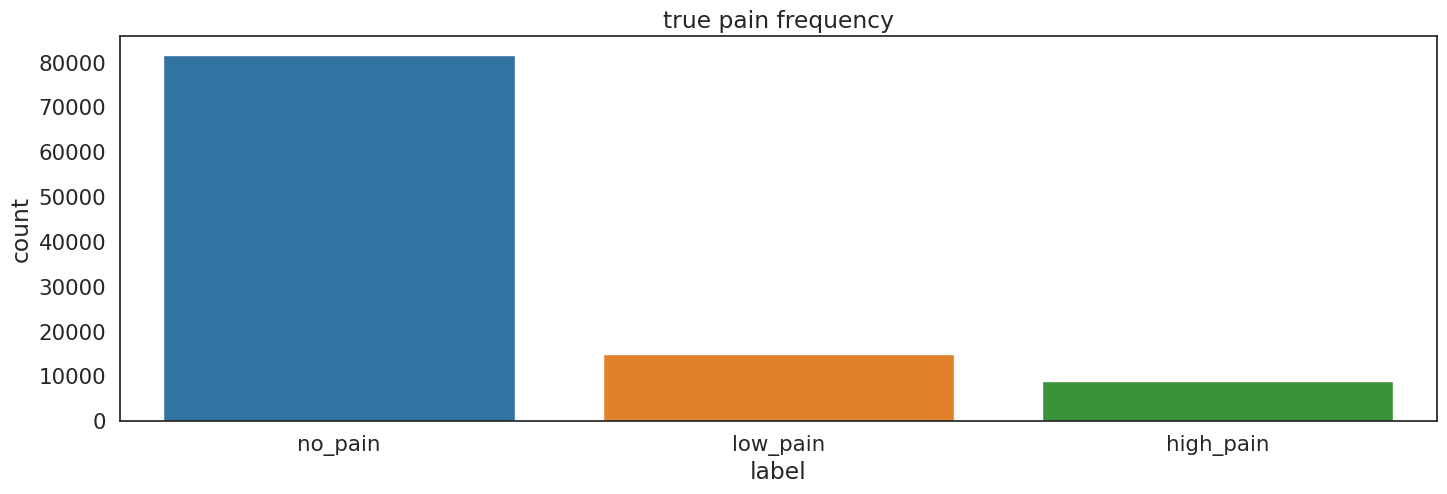

In [ ]:
# Visualise the count of timestamps for each activity
plt.figure(figsize=(17, 5))
sns.countplot(
    x='label',
    data=df,
    order=df['label'].value_counts().index,
    palette='tab10'
)

# Set the title of the plot
plt.title('true pain frequency')

# Display the plot
plt.show()

Number of unique users: 661


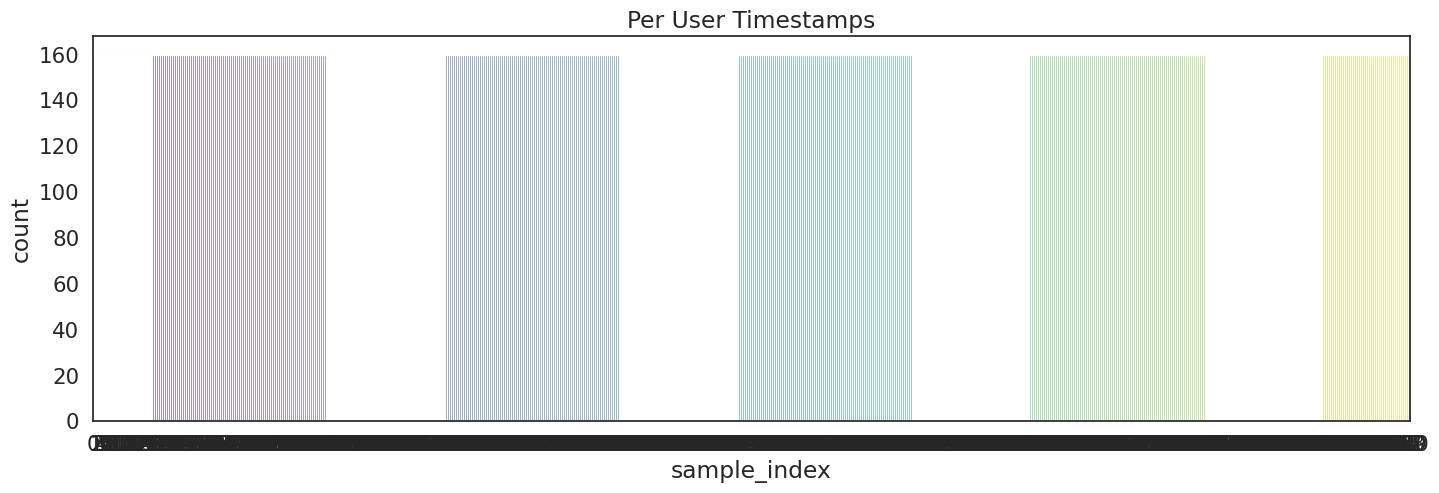

In [ ]:
# Count the number of unique users
n_users = len(df['sample_index'].unique())
print(f"Number of unique users: {n_users}")

# Create a custom colour map with distinct colours for each user
colors = plt.cm.viridis(np.linspace(0, 1, n_users))

# Visualise the count of timestamps for each user
plt.figure(figsize=(17, 5))
sns.countplot(
    x='sample_index',
    data=df,
    palette=colors
)

# Set the title of the plot
plt.title('Per User Timestamps')

# Display the plot
plt.show()

##### Distribution of `n_legs`, `n_hands`, and `n_eyes` by Label

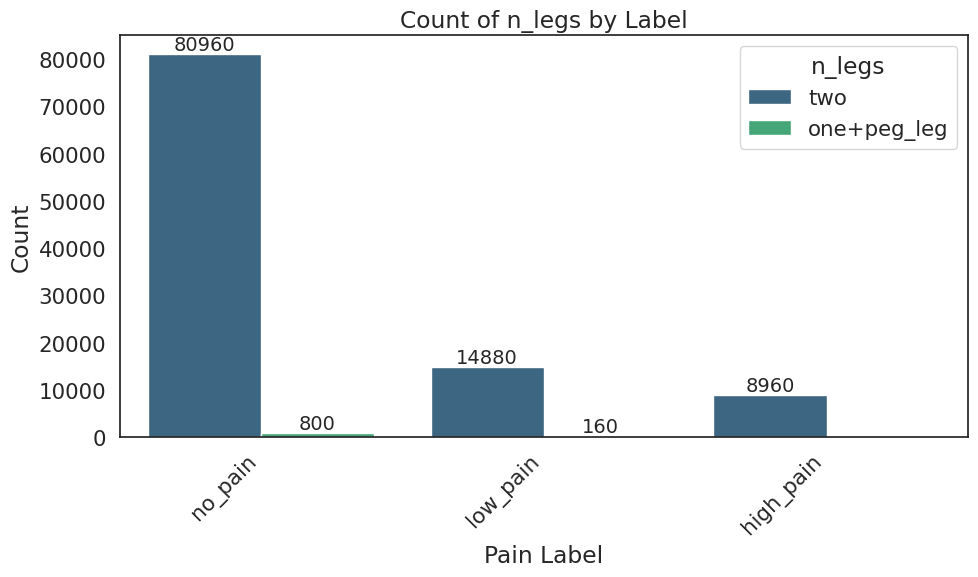

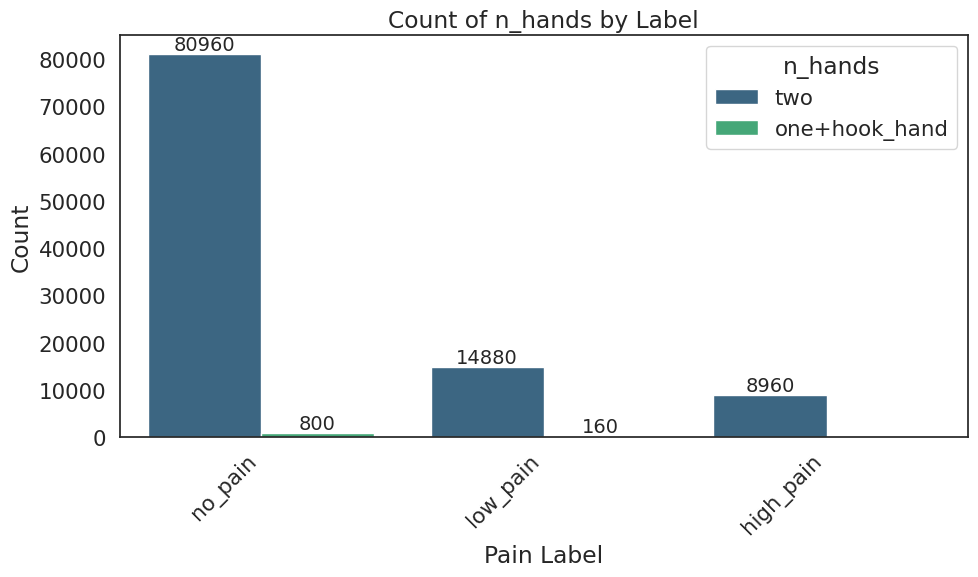

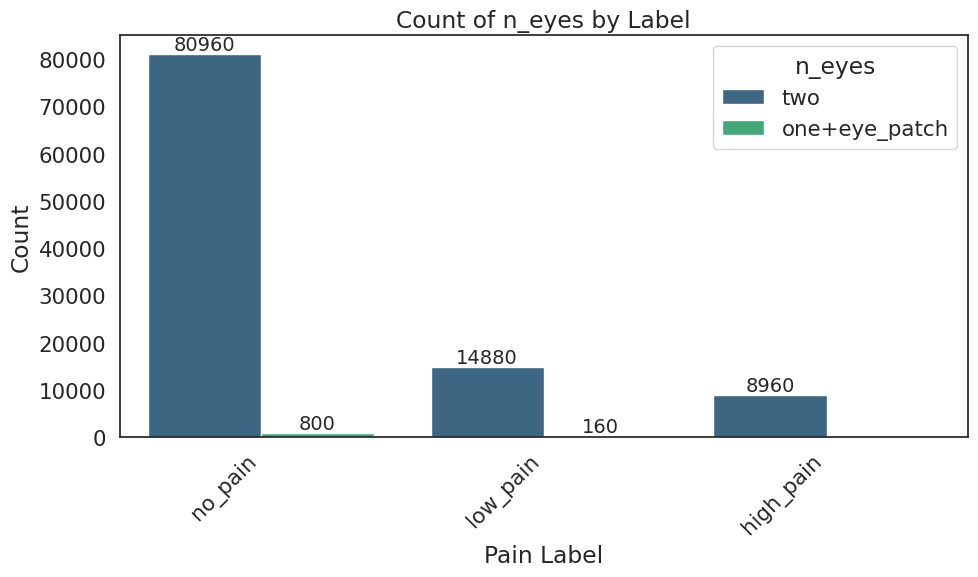

In [ ]:
#not gonna lie, complitely gemini crafted
categorical_features = ['n_legs', 'n_hands', 'n_eyes']

for feature in categorical_features:
    plt.figure(figsize=(10, 6))
    ax = sns.countplot(data=df, x='label', hue=feature, palette='viridis')
    plt.title(f'Count of {feature} by Label')
    plt.xlabel('Pain Label')
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title=feature)

    # Add count labels on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f')

    plt.tight_layout()
    plt.show()

In [ ]:
# Define a function to inspect sensor data for a specific activity
def inspect_label(label, df, n_users=None, max_timesteps_per_user=160):
    # Get all joint columns dynamically
    joint_columns = [col for col in df.columns if col.startswith('joint_')]

    # Filter the DataFrame for the specified label
    labeled_data = df[df['label'] == label]

    unique_sample_indices = labeled_data['sample_index'].unique()
    if n_users is not None:
        # Select data only from the first n_users unique sample_indices
        selected_sample_indices = unique_sample_indices[:n_users]
    else:
        # If n_users is not specified, use all unique sample_indices for the label
        selected_sample_indices = unique_sample_indices

    if len(selected_sample_indices) == 0:
        print(f"No users found for label '{label}' with the given criteria.")
        return

    # Determine grid size for subplots
    num_joints = len(joint_columns)
    ncols = 4 # Number of columns in the subplot grid
    nrows = (num_joints + ncols - 1) // ncols # Calculate rows needed (ceiling division)

    # Create a figure and a grid of subplots
    # sharex=True ensures that all subplots share the same x-axis (time)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows), sharex=True)
    axes = axes.flatten() # Flatten the 2D array of axes for easier iteration

    # Set a main title for the entire figure
    fig.suptitle(f'Sensor Data for Label: {label} (showing {len(selected_sample_indices)} users)', y=1.02)

    # Iterate through each joint column to create its own subplot
    for i, joint_col in enumerate(joint_columns):
        if i >= len(axes): # Stop if we run out of allocated axes (e.g., if num_joints < nrows*ncols)
            break
        ax = axes[i]
        ax.set_title(joint_col, fontsize='medium') # Set title for individual joint plot
        # ax.set_xlabel('Time Step') # X-label only on bottom row if sharex=True is used
        # ax.set_ylabel('Value') # Y-label only on left-most column

        # Iterate through each selected user and plot their data for the current joint
        for user_idx in selected_sample_indices:
            user_data = labeled_data[labeled_data['sample_index'] == user_idx]
            # Apply max_timesteps_per_user limit if specified
            if max_timesteps_per_user is not None:
                user_data = user_data.head(max_timesteps_per_user)

            if not user_data.empty:
                ax.plot(user_data['time'], user_data[joint_col], label=f'User {user_idx}')

        ax.legend(loc='best', fontsize='x-small') # Add legend for each user in each joint plot
        ax.grid(True, linestyle='--', alpha=0.6) # Add a grid for readability

    # Hide any unused subplots in the grid
    for j in range(i + 1, len(axes)): # Loop from the next axis after the last plotted joint
        fig.delaxes(axes[j])

    # Adjust layout to prevent overlapping titles/labels, leaving space for the suptitle
    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    plt.show()

#### Inspecting Sensor Data for Pirates with Specific Characteristics (2 legs, 2 hands, 2 eyes)

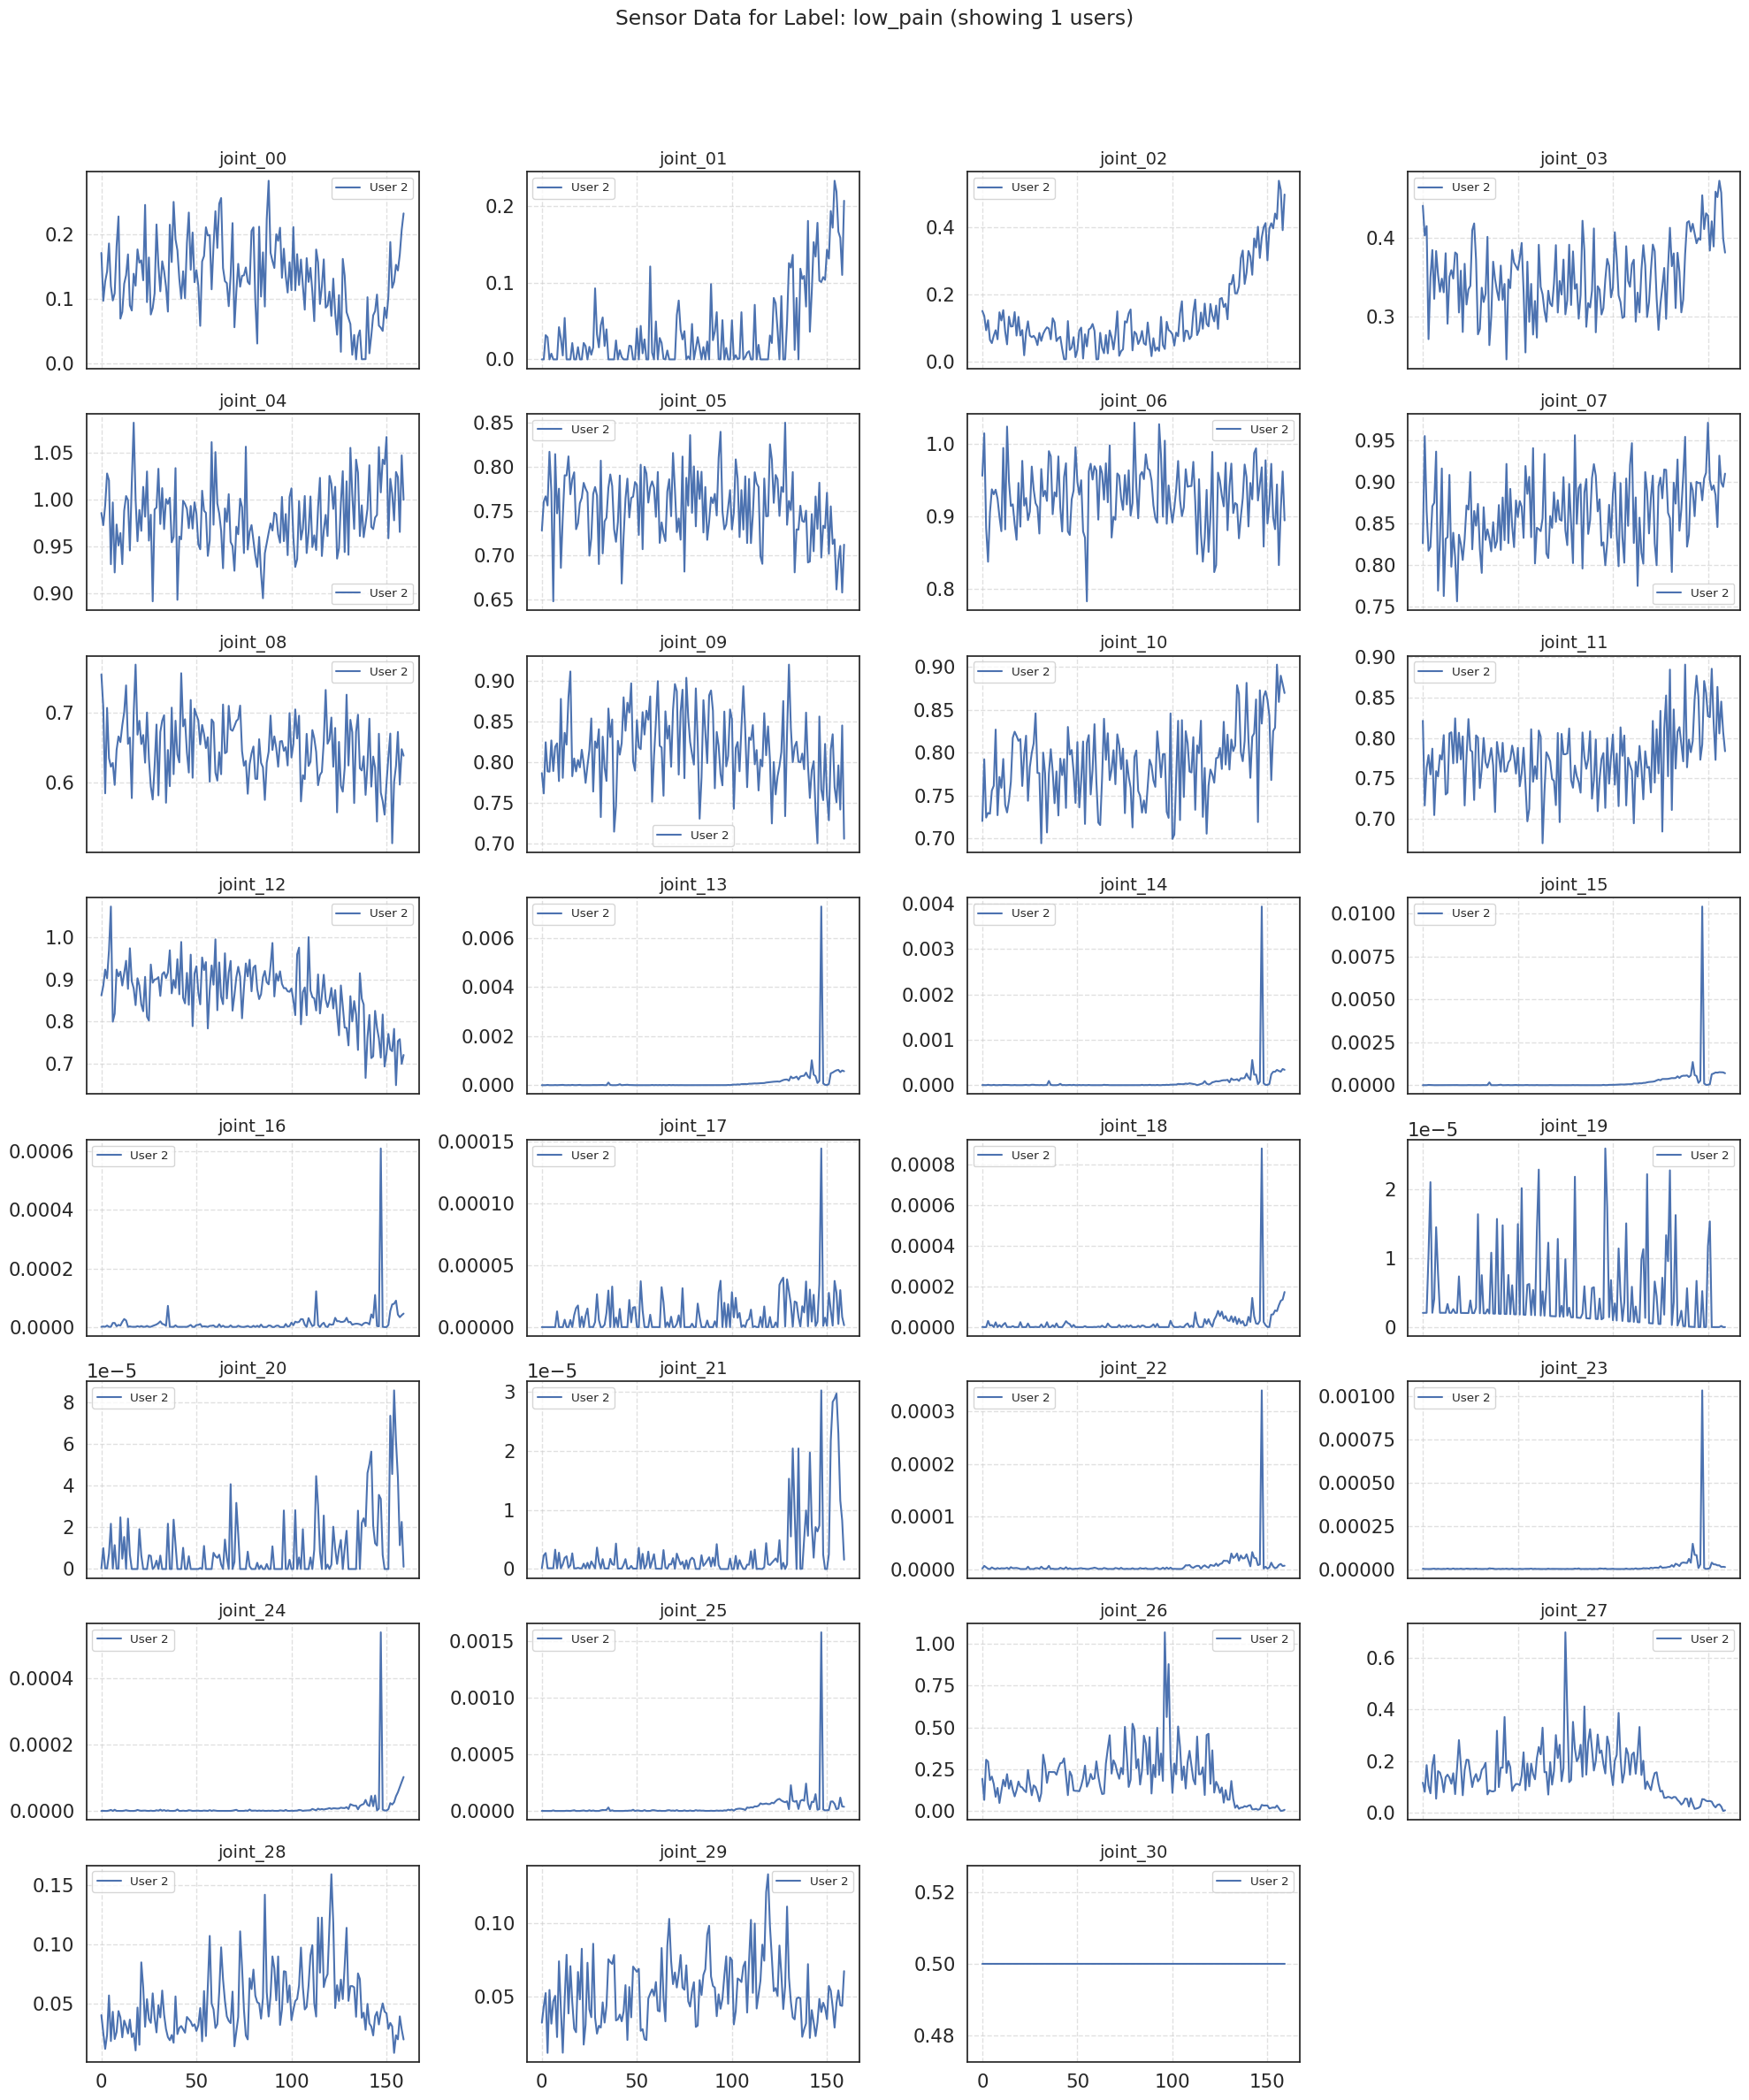

In [ ]:
inspect_label('low_pain', df, 1)

Shape of filtered DataFrame: (104800, 53)


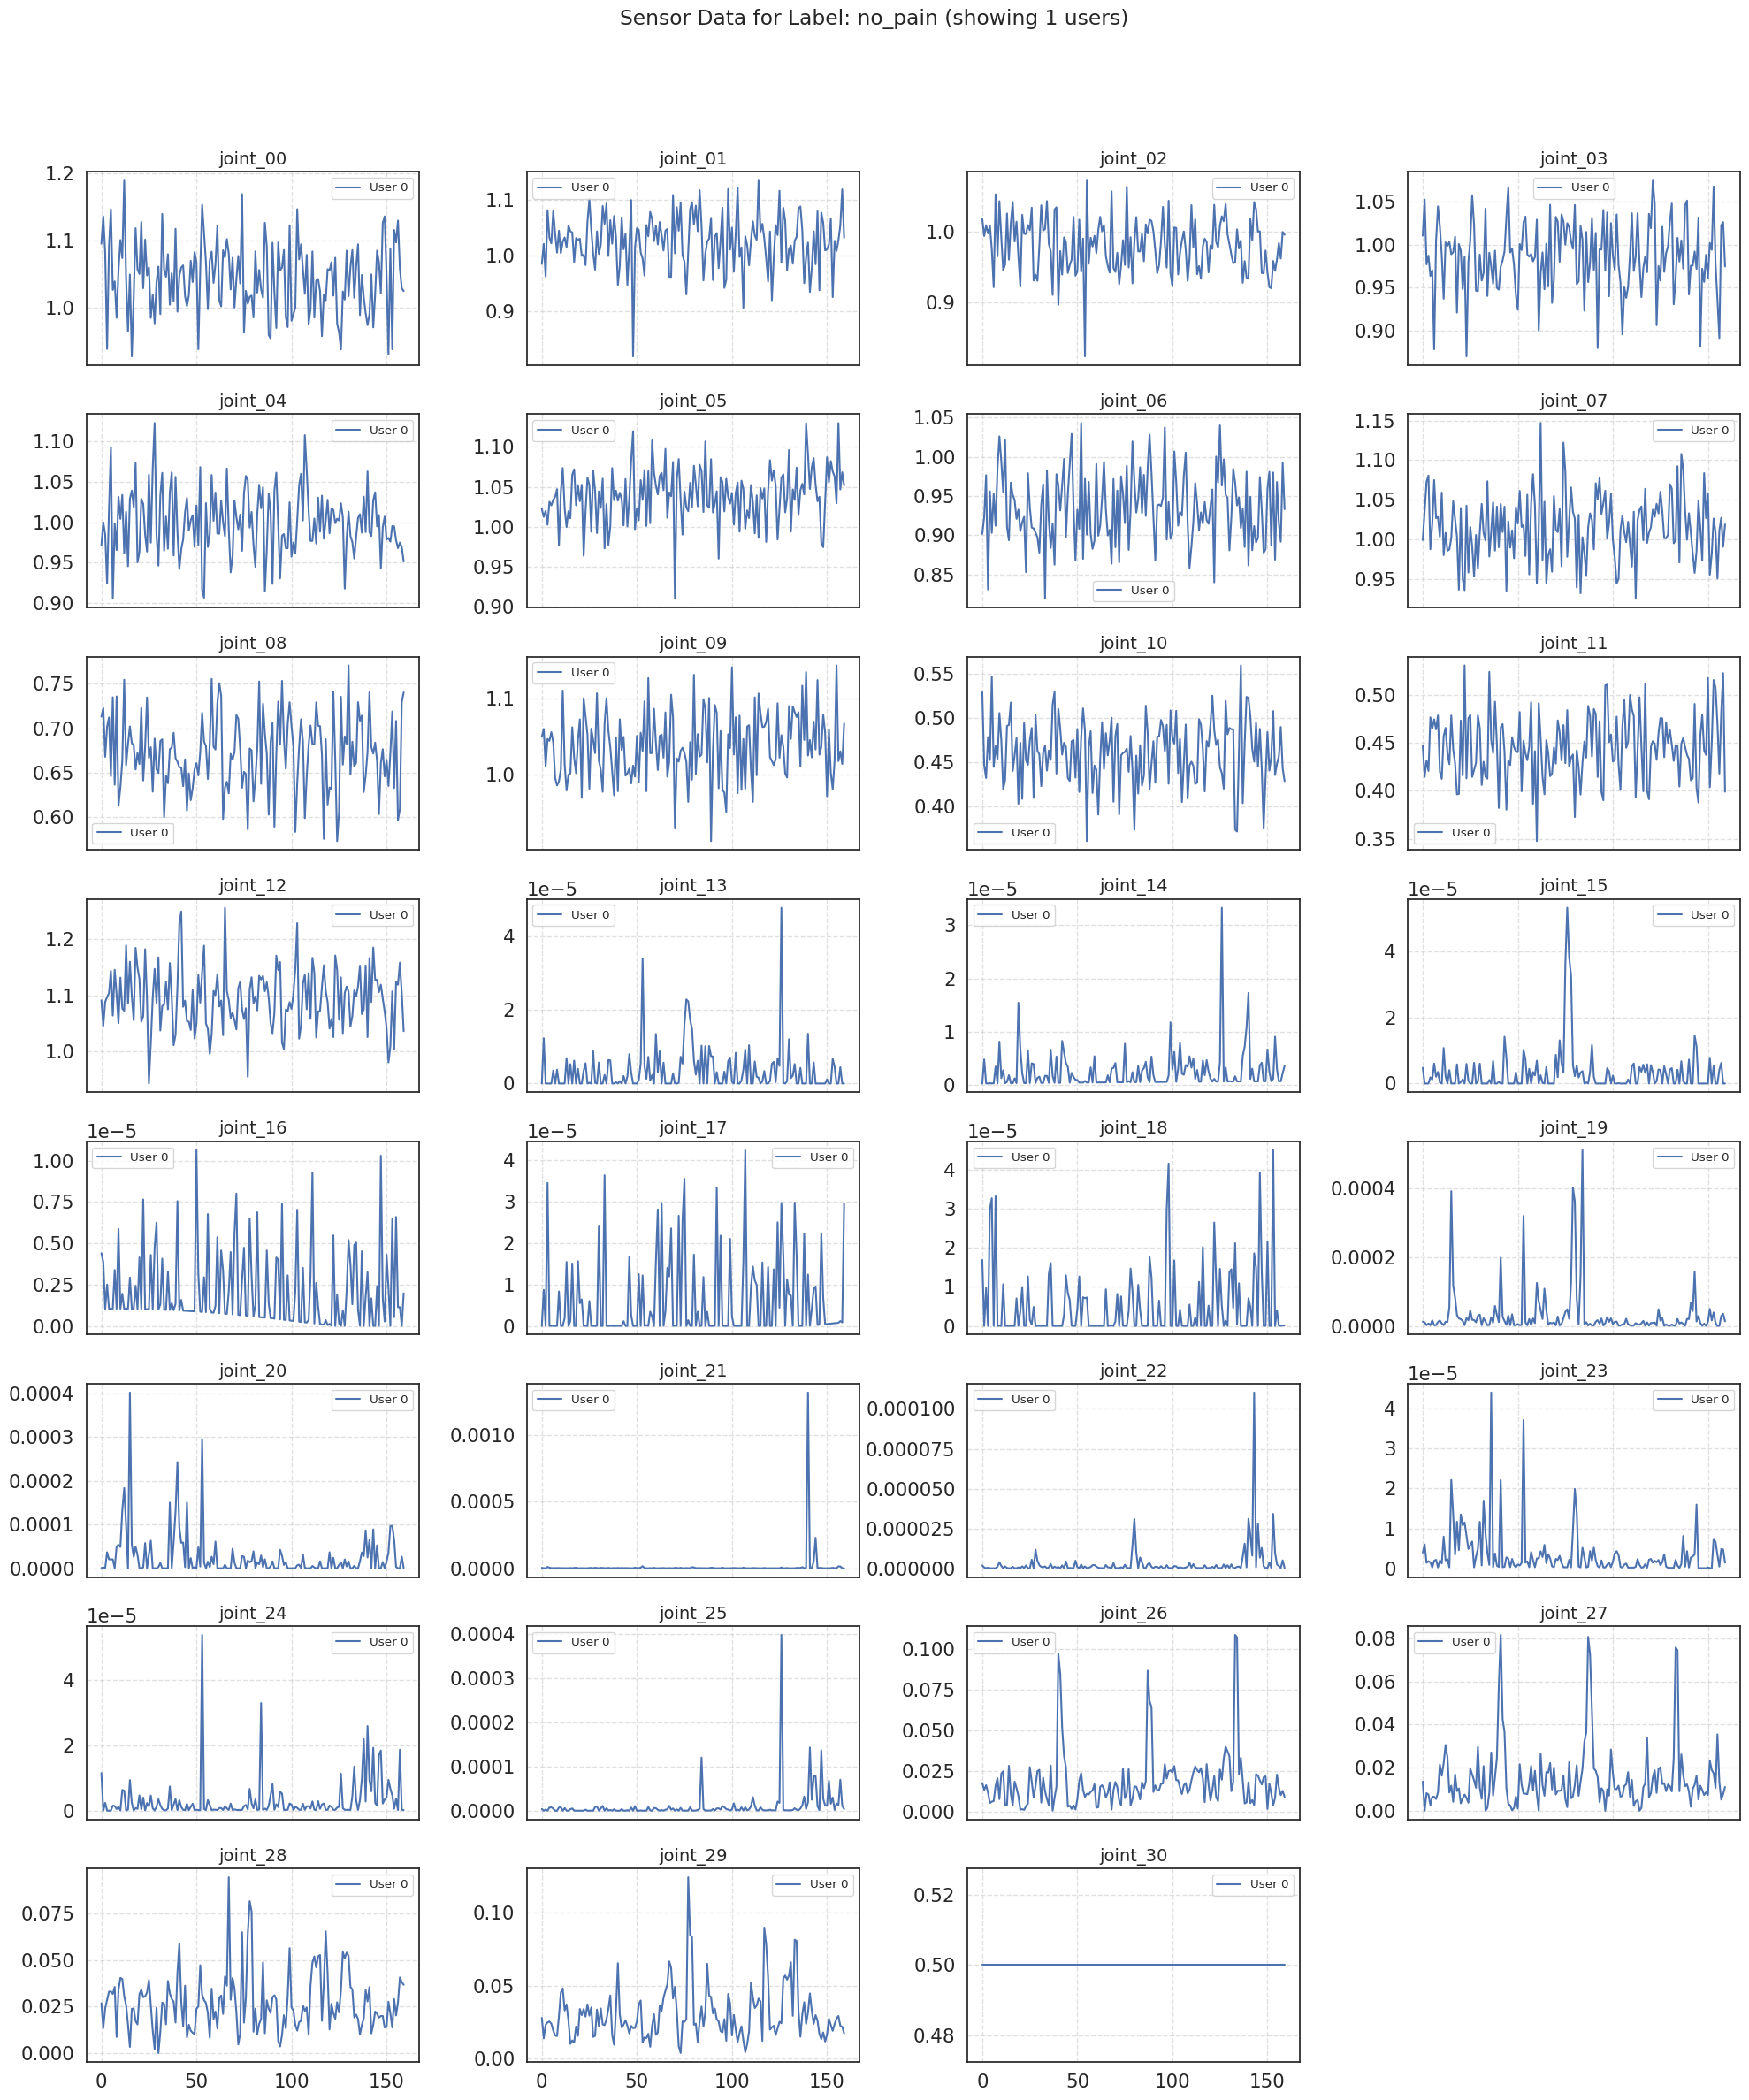

In [ ]:
# Filter the DataFrame for pirates with 'two' legs, 'two' hands, and 'two' eyes
filtered_df_specific_pirates = df[
    (df['n_legs'] == 'two') &
    (df['n_hands'] == 'two') &
    (df['n_eyes'] == 'two')
]

print(f"Shape of filtered DataFrame: {filtered_df_specific_pirates.shape}")

# Inspect the 'no_pain' activity for these filtered pirates
inspect_label('no_pain', filtered_df_specific_pirates, 1)

## 🥦 **Data Processing (obs run)**

In [11]:
# Get unique user IDs
unique_users = df['sample_index'].unique()

# Get the label and has_any_disability for each unique user
# Create a DataFrame where index is sample_index and values are label and has_any_disability
user_level_strat_info = df.drop_duplicates(subset=['sample_index']).set_index('sample_index')[['label', 'has_any_disability']]

# Create a combined stratification key
user_level_strat_info['combined_strat_key'] = user_level_strat_info['label'].astype(str) + '_' + user_level_strat_info['has_any_disability'].astype(str)

# Get the stratification labels as a Series for unique users
stratify_series = user_level_strat_info.loc[unique_users]['combined_strat_key']

# Identify strata with only one member (these cause ValueError in train_test_split)
strat_counts = stratify_series.value_counts()
single_member_strata_keys = strat_counts[strat_counts == 1].index.tolist()

# Separate users into 'splittable' (can be stratified) and 'unsplittable' (single-member strata)
splittable_users_mask = ~stratify_series.isin(single_member_strata_keys)
splittable_users = unique_users[splittable_users_mask]
unsplittable_users = unique_users[~splittable_users_mask]

# Get stratify labels for the splittable users
stratify_labels_for_splittable = stratify_series.loc[splittable_users].values

# Calculate a proportional test_size based on N_VAL_USERS and total unique users
# This makes the split more robust when dealing with varying class sizes
test_size_ratio = N_VAL_USERS / len(unique_users)

# Perform stratified split on the splittable users
# Only attempt split if there are enough splittable users and valid strata
if len(splittable_users) > 1 and len(np.unique(stratify_labels_for_splittable)) > 1:
    train_users_main, val_users_main = train_test_split(
        splittable_users,
        test_size=test_size_ratio, # Use a proportion for test_size
        stratify=stratify_labels_for_splittable,
        random_state=SEED
    )
else:
    # If not enough splittable users for stratified split, put them all in train
    train_users_main = splittable_users
    val_users_main = np.array([])

# Combine the results, adding unsplittable users (single-member strata) to the training set
train_users = np.concatenate((train_users_main, unsplittable_users))
val_users = val_users_main

# Split the dataset into training, validation, and test sets based on user IDs
df_train = df[df['sample_index'].isin(train_users)]
df_val = df[df['sample_index'].isin(val_users)]
df_test = dfTest

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')
print(f'Test set shape: {df_test.shape}')

Training set shape: (89760, 45)
Validation set shape: (16000, 45)
Test set shape: (211840, 44)


In [12]:
# Initialise a dictionary to count occurrences of each activity in the training set
training_labels = {
   'no_pain':0,
   'low_pain':0,
   'high_pain':0
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = df_train[df_train['sample_index'] == id]['label'].values[0]
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'no_pain': 433, 'low_pain': 80, 'high_pain': 48}


In [13]:
# Initialise a dictionary to count occurrences of each activity in the validation set
val_labels = {
   'no_pain':0,
   'low_pain':0,
   'high_pain':0
}

# Count occurrences of each activity for unique IDs in the validation set
for id in df_val['sample_index'].unique():
    label = df_val[df_val['sample_index'] == id]['label'].values[0]
    val_labels[label] += 1

# Print the distribution of validation labels
print('Validation labels:', val_labels)

Validation labels: {'no_pain': 78, 'low_pain': 14, 'high_pain': 8}


In [14]:
label_mapping = {
     'no_pain':0,
   'low_pain':1,
   'high_pain':2
}

# Map activity names to integers in the training set
df_train['label'] = df_train['label'].map(label_mapping)

# Map activity names to integers in the validation set
df_val['label'] = df_val['label'].map(label_mapping)

# Create the inverse mapping immediately after label_mapping
label_inverse_mapping = {v: k for k, v in label_mapping.items()}

'''# Map activity names to integers in the test set
df_test['label'] = df_test['label'].map(label_mapping)'''

"# Map activity names to integers in the test set\ndf_test['label'] = df_test['label'].map(label_mapping)"

In [15]:
from sklearn.preprocessing import StandardScaler

# Define the columns to be normalised
scale_columns = []
for col in df_train.columns:
    if col.startswith('joint_'):
        scale_columns.append(col)

scaler = StandardScaler()

scaler.fit(df_train[scale_columns])

df_train[scale_columns] = scaler.transform(df_train[scale_columns])
df_val[scale_columns] = scaler.transform(df_val[scale_columns])
df_test[scale_columns] = scaler.transform(df_test[scale_columns])

print("Dati normalizzati con StandardScaler (Z-Score).")

Dati normalizzati con StandardScaler (Z-Score).


In [16]:
'''def build_sequences(df, window=40, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Check if the 'label' column exists in the DataFrame
    has_labels = 'label' in df.columns

    # Define feature columns dynamically based on the dataframe structure
    feature_columns = [col for col in df.columns if col.startswith('joint_')] + \
                      ['has_any_disability']#,'hour_sin','hour_cos']

    if PAIN_SURVEY_COLUMNS:
          feature_columns += [col for col in df.columns if col.startswith('pain_survey_')]


    num_features = len(feature_columns)

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][feature_columns].values

        # Retrieve the activity label for the current ID if labels are available
        current_label = None
        if has_labels:
            current_label = df[df['sample_index'] == id]['label'].values[0]
        else:
            # For test data where labels are not available, use a dummy value (e.g., 0)
            # This placeholder will be replaced by predictions later.
            current_label = 0

        # Calculate padding length to ensure full windows
        padding_len = (window - (len(temp) % window)) % window

        # Create zero padding and concatenate with the data
        padding = np.zeros((padding_len, num_features), dtype='float32')
        temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            labels.append(current_label) # Append the actual label or the dummy label
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels'''

"def build_sequences(df, window=40, stride=5):\n    # Sanity check to ensure the window is divisible by the stride\n    assert window % stride == 0\n\n    # Initialise lists to store sequences and their corresponding labels\n    dataset = []\n    labels = []\n\n    # Check if the 'label' column exists in the DataFrame\n    has_labels = 'label' in df.columns\n\n    # Define feature columns dynamically based on the dataframe structure\n    feature_columns = [col for col in df.columns if col.startswith('joint_')] +                       ['has_any_disability']#,'hour_sin','hour_cos']\n\n    if PAIN_SURVEY_COLUMNS:\n          feature_columns += [col for col in df.columns if col.startswith('pain_survey_')]\n\n\n    num_features = len(feature_columns)\n\n    # Iterate over unique IDs in the DataFrame\n    for id in df['sample_index'].unique():\n        # Extract sensor data for the current ID\n        temp = df[df['sample_index'] == id][feature_columns].values\n\n        # Retrieve the activi

In [17]:
def build_sequences(df, window=40, stride=5, label_column='label', pain_survey_columns_flag=True, is_test=False):
    # Sanity check
    assert window % stride == 0

    # Initialise lists
    dataset_dynamic = []
    dataset_static = []
    labels = []

    has_labels = (label_column in df.columns) and (not is_test)

    # --- SEPARATE FEATURE COLUMNS ---
    dynamic_cols = [col for col in df.columns if col.startswith(('joint_', 'pain_survey_'))]

    static_cols = ['has_any_disability']

    # Cyclical time features are also dynamic, add them if you use them
    dynamic_cols += ['hour_sin', 'hour_cos']
    # ---

    num_dynamic_features = len(dynamic_cols)
    num_static_features = len(static_cols)

    for id in df['sample_index'].unique():
        # Get dynamic data for the user
        temp_dynamic = df[df['sample_index'] == id][dynamic_cols].values

        # Get static data (it's the same for all timesteps, so just take the first row)
        temp_static = df[df['sample_index'] == id][static_cols].iloc[0].values

        current_label = 0
        if has_labels:
            current_label = df[df['sample_index'] == id]['label'].values[0]

        # Calculate padding length
        padding_len = (window - (len(temp_dynamic) % window)) % window

        # Create zero padding for dynamic features
        padding_dynamic = np.zeros((padding_len, num_dynamic_features), dtype='float32')
        temp_dynamic = np.concatenate((temp_dynamic, padding_dynamic))

        # Build windows
        idx = 0
        while idx + window <= len(temp_dynamic):
            dataset_dynamic.append(temp_dynamic[idx:idx + window])
            dataset_static.append(temp_static) # Append the same static vector for each window
            labels.append(current_label)
            idx += stride

    dataset_dynamic = np.array(dataset_dynamic)
    dataset_static = np.array(dataset_static)
    labels = np.array(labels)

    return dataset_dynamic, dataset_static, labels

In [18]:
'''# Generate sequences and labels for the training set
X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the validation set
X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the test set
X_test, y_test = build_sequences(df_test, WINDOW_SIZE, STRIDE)'''


'# Generate sequences and labels for the training set\nX_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)\n\n# Generate sequences and labels for the validation set\nX_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)\n\n# Generate sequences and labels for the test set\nX_test, y_test = build_sequences(df_test, WINDOW_SIZE, STRIDE)'

In [19]:
# Generate sequences and labels for the training set
X_train_dyn, X_train_static, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the validation set
X_val_dyn, X_val_static, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the test set
X_test_dyn, X_test_static, y_test = build_sequences(df_test, WINDOW_SIZE, STRIDE)

In [20]:
'''# Define the input shape based on the training data
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))'''

'# Define the input shape based on the training data\ninput_shape = X_train.shape[1:]\n\n# Define the number of classes based on the categorical labels\nnum_classes = len(np.unique(y_train))'

In [21]:
# Define the input shape based on the training data
sequence_input_shape = X_train_dyn.shape[1:]
static_input_shape = X_train_static.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

In [22]:
'''# Convert numpy arrays to PyTorch datasets (pairs features with labels)
# Explicitly cast to .float() to ensure torch.float32 type for all input tensors
train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))
test_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))'''

'# Convert numpy arrays to PyTorch datasets (pairs features with labels)\n# Explicitly cast to .float() to ensure torch.float32 type for all input tensors\ntrain_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train))\nval_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))\ntest_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))'

In [23]:
# Convert numpy arrays to PyTorch datasets
train_ds = TensorDataset(
    torch.from_numpy(X_train_dyn).float(),
    torch.from_numpy(X_train_static).float(),
    torch.from_numpy(y_train)
)
val_ds = TensorDataset(
    torch.from_numpy(X_val_dyn).float(),
    torch.from_numpy(X_val_static).float(),
    torch.from_numpy(y_val)
)
test_ds = TensorDataset(
    torch.from_numpy(X_test_dyn).float(),
    torch.from_numpy(X_test_static).float(),
    torch.from_numpy(y_test)
)

### experimenting:


In [24]:
# here I need to create a weight vector with weights in correspondence of the train_ds samples
weights_vector = []

# Get user-level information (has_any_disability and original string label) from the full 'df' DataFrame
# This ensures we get the original string label before df_train's labels were mapped to integers.
user_level_info_df = df[df['sample_index'].isin(df_train['sample_index'].unique())]
user_level_info_df = user_level_info_df[['sample_index', 'has_any_disability', 'label']].drop_duplicates(subset=['sample_index']).set_index('sample_index')

# Calculate weights for 'pirate' users
pirate_users_info = user_level_info_df[user_level_info_df['has_any_disability'] == 1]
pirate_label_counts = pirate_users_info['label'].value_counts()
total_pirate_users = pirate_label_counts.sum()
# Calculate inverse frequency weights
weights_pirate = {
    label: (1.0 / count) * (total_pirate_users / len(pirate_label_counts))
    for label, count in pirate_label_counts.items()
}
# Normalize the weights so they sum to 1 for each category (optional, but good practice)
sum_weights_pirate = sum(weights_pirate.values())
weights_pirate = {label: weight / sum_weights_pirate for label, weight in weights_pirate.items()}


# Calculate weights for 'no_pirate' users
no_pirate_users_info = user_level_info_df[user_level_info_df['has_any_disability'] == 0]
no_pirate_label_counts = no_pirate_users_info['label'].value_counts()
total_no_pirate_users = no_pirate_label_counts.sum()
# Calculate inverse frequency weights
weights_no_pirate = {
    label: (1.0 / count) * (total_no_pirate_users / len(no_pirate_label_counts))
    for label, count in no_pirate_label_counts.items()
}
# Normalize the weights so they sum to 1 for each category (optional, but good practice)
sum_weights_no_pirate = sum(weights_no_pirate.values())
weights_no_pirate = {label: weight / sum_weights_no_pirate for label, weight in weights_no_pirate.items()}

#manually increment weights for high pain label
#weights_no_pirate['high_pain'] += 1.0

# Reconstruct the mapping from sequence index in train_ds to its original sample_index (user_id)
# This follows the logic of the build_sequences function to identify which user each sequence belongs to.
original_sample_indices_for_train_sequences = []
for user_id in df_train['sample_index'].unique():
    # Get the length of the data for this user from df_train
    user_data_len = len(df_train[df_train['sample_index'] == user_id])

    # Padding logic from build_sequences function (using global WINDOW_SIZE and STRIDE)
    padding_len = (WINDOW_SIZE - (user_data_len % WINDOW_SIZE)) % WINDOW_SIZE
    total_len_after_padding = user_data_len + padding_len

    idx = 0
    while idx + WINDOW_SIZE <= total_len_after_padding:
        original_sample_indices_for_train_sequences.append(user_id)
        idx += STRIDE

# Verify the length match, crucial for WeightedRandomSampler
if len(original_sample_indices_for_train_sequences) != len(train_ds):
    raise ValueError(
        "Mismatch in number of sequences for weight calculation and actual train_ds length.\n"
        "This indicates an inconsistency in how sequences are generated or accounted for."
        f"Expected {len(train_ds)} sequences, but got {len(original_sample_indices_for_train_sequences)}."
    )


# Now iterate through the reconstructed sequence-to-user mapping and assign weights
for sequence_original_sample_index in original_sample_indices_for_train_sequences:
    # Retrieve user-level attributes using the original sample_index
    has_disability = user_level_info_df.loc[sequence_original_sample_index, 'has_any_disability']
    original_string_label = user_level_info_df.loc[sequence_original_sample_index, 'label']

    # Determine the weight based on disability status and the original string label
    if has_disability:
        weight = weights_pirate[original_string_label]
    else:
        weight = weights_no_pirate[original_string_label]

    weights_vector.append(weight)

# Convert the list of weights to a PyTorch tensor
weights_vector = torch.tensor(weights_vector, dtype=torch.float32)

print(weights_vector.max())

tensor(0.8000)


### non experimenting

In [25]:
def make_loader(ds, batch_size, shuffle, drop_last, sampler=None):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = cpu_cores-1

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle and sampler is None,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=5,  # Load 4 batches ahead
        sampler=sampler
    )

In [26]:
# Create a WeightedRandomSampler for the training data
# This sampler uses the pre-calculated weights_vector to balance classes during training
weighted_sampler = WeightedRandomSampler(weights=weights_vector, num_samples=len(train_ds), replacement=True)

# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False, sampler=weighted_sampler)
#train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [27]:
# Get one batch from the training data loader
for xb_dyn, xb_static, yb in train_loader:
    print("Dynamic Features batch shape:", xb_dyn.shape)
    print("Static Features batch shape:", xb_static.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Dynamic Features batch shape: torch.Size([128, 32, 37])
Static Features batch shape: torch.Size([128, 1])
Labels batch shape: torch.Size([128])


## **Exploring Focal Loss**

In [28]:
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

        if isinstance(alpha, (float, int)): # Handle scalar alpha
            self.alpha = torch.tensor([alpha, 1 - alpha])
        if isinstance(alpha, torch.Tensor):
            self.alpha = alpha.to(device)

    def forward(self, inputs, targets):
        BCE_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)
        F_loss = self.alpha[targets] * (1-pt)**self.gamma * BCE_loss

        if self.reduction == 'mean':
            return F_loss.mean()
        elif self.reduction == 'sum':
            return F_loss.sum()
        else:
            return F_loss

print("FocalLoss class defined.")

FocalLoss class defined.


In [29]:
class Jitter(nn.Module):
    """
    Applies random noise (jittering) to the input tensor.
    Only applied during training.
    """
    def __init__(self, sigma=0.01):
        super().__init__()
        self.sigma = sigma

    def forward(self, x):
        if self.training:
            # Add Gaussian noise
            return x + (torch.randn_like(x) * self.sigma)
        return x

In [30]:
import torch.nn.functional as F

class Attention(nn.Module):
    def __init__(self, hidden_size):
        """
        Inizializza un semplice meccanismo di attention additiva (o a punteggio).
        :param hidden_size: La dimensione dello stato nascosto dell'RNN (o rnn_output_feature_size).
        """
        super(Attention, self).__init__()
        # Usiamo un singolo strato lineare per calcolare i punteggi di attention
        self.attention_weights = nn.Linear(hidden_size, 1)

    def forward(self, rnn_output_sequence):
        """
        Forward pass per l'attention.
        :param rnn_output_sequence: Output dell'RNN. Shape: (batch_size, seq_len, hidden_size)
        :return: Tupla di (context_vector, attn_weights)
                 context_vector shape: (batch_size, hidden_size)
                 attn_weights shape: (batch_size, seq_len)
        """

        # Calcola i punteggi di attention
        # Input (batch, seq_len, hidden_size) -> Output (batch, seq_len, 1)
        scores = self.attention_weights(rnn_output_sequence).squeeze(2)

        # Applica Softmax per ottenere i pesi (weights)
        # Shape: (batch_size, seq_len)
        attn_weights = F.softmax(scores, dim=1)

        # Calcola il vettore di contesto (somma pesata degli output dell'RNN)
        # torch.bmm (batch matrix multiplication):
        # (batch, 1, seq_len) bmm (batch, seq_len, hidden_size) -> (batch, 1, hidden_size)
        context_vector = torch.bmm(attn_weights.unsqueeze(1), rnn_output_sequence).squeeze(1)

        # context_vector shape: (batch_size, hidden_size)
        return context_vector, attn_weights

## 🛠 **Finally building the model (Run and don't modify)**

In [31]:
class CNNFeatureExtractor(nn.Module):
    def __init__(
        self,
        input_size, # This will be num_features
        sequence_length, # This will be WINDOW_SIZE
        num_filters=128,
        kernel_size=5,
        stride=1,
        padding=2, # To maintain sequence length if stride=1
        num_cnn_layers=2,
        pool_size=2,
        dropout_rate=0.3 # Dropout rate, but not used directly in this feature extractor
    ):
        super().__init__()

        self.conv_layers = nn.ModuleList()
        # First layer converts input_size (features) to num_filters
        # Conv1d expects (batch_size, in_channels, sequence_length)
        self.conv_layers.append(nn.Conv1d(input_size, num_filters, kernel_size=kernel_size, stride=stride, padding=padding))
        self.conv_layers.append(nn.ReLU())
        self.conv_layers.append(nn.MaxPool1d(kernel_size=pool_size))

        # Remaining layers keep num_filters as in_channels and out_channels
        for _ in range(num_cnn_layers - 1):
            self.conv_layers.append(nn.Conv1d(num_filters, num_filters, kernel_size=kernel_size, stride=stride, padding=padding))
            self.conv_layers.append(nn.ReLU())
            self.conv_layers.append(nn.MaxPool1d(kernel_size=pool_size))

        # Calculate output size after convolutional and pooling layers accurately
        current_sequence_length = sequence_length
        for _ in range(num_cnn_layers):
            # After Conv1d (with stride from init params, dilation=1)
            current_sequence_length = (current_sequence_length + 2 * padding - (kernel_size - 1) - 1) // stride + 1

            # After MaxPool1d (with kernel_size=pool_size and default stride=pool_size)
            current_sequence_length = (current_sequence_length - pool_size) // pool_size + 1

            if current_sequence_length < 1:
                raise ValueError("Sequence length became too small after convolution/pooling. Consider adjusting num_cnn_layers, window_size, kernel_size, padding, or pool_size.")

        # The output feature size will be num_filters * reduced_sequence_length
        self.output_feature_size = num_filters
        self.output_seq_len = current_sequence_length

    def forward(self, x):
        # x shape: (batch_size, sequence_length, input_size)
        # Conv1d expects (batch_size, in_channels, sequence_length)
        x = x.permute(0, 2, 1) # Permute to (batch_size, input_size, sequence_length)

        for layer in self.conv_layers:
            x = layer(x)

        # Flatten all dimensions except batch to get the feature vector
        # This feature vector will be passed to the RNN or directly to a classifier if used as a standalone component
        return x.permute(0, 2, 1)


class CNNClassifier(nn.Module):
    def __init__(
        self,
        input_size,
        sequence_length,
        num_classes,
        num_filters=128,
        kernel_size=5,
        stride=1,
        padding=2,
        num_cnn_layers=2,
        pool_size=2,
        dropout_rate=0.3
    ):
        super().__init__()
        self.feature_extractor = CNNFeatureExtractor(
            input_size=input_size,
            sequence_length=sequence_length,
            num_filters=num_filters,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            num_cnn_layers=num_cnn_layers,
            pool_size=pool_size
        )
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(self.feature_extractor.output_feature_size, num_classes)

    def forward(self, x):
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.classifier(features)
        return logits


class RNNFeatureExtractor(nn.Module):
    """
    Generic RNN feature extractor (RNN, LSTM, GRU).
    Outputs the last hidden state for use as features.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            rnn_type='LSTM',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,
            dropout_rate=0.2,
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        dropout_val = dropout_rate if num_layers > 1 else 0

        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        if self.bidirectional:
            self.output_feature_size = hidden_size * 2
        else:
            self.output_feature_size = hidden_size

    def forward(self, x):
        rnn_out, hidden = self.rnn(x)
        return rnn_out

class RecurrentClassifier(nn.Module):
    def __init__(
        self,
        sequence_input_size, # Changed this from input_size
        static_input_size,   # Added this argument
        hidden_size,
        num_layers,
        num_classes,
        rnn_type='LSTM',
        bidirectional=False,
        dropout_rate=0.2,
        jitter_sigma=0.1
    ):
        super().__init__()
        self.jitter = Jitter(sigma=jitter_sigma) # <-- Add this
        self.feature_extractor = RNNFeatureExtractor(
            input_size=sequence_input_size, # <-- Pass sequence_input_size here
            hidden_size=hidden_size,
            num_layers=num_layers,
            rnn_type=rnn_type,
            bidirectional=bidirectional,
            dropout_rate=dropout_rate
        )
        self.dropout = nn.Dropout(dropout_rate)
        classifier_input_size = self.feature_extractor.output_feature_size + static_input_size # <-- Use static_input_size here
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x_seq, x_static):
        x_seq = self.jitter(x_seq) # <-- Apply jitter first

        seq_features = self.feature_extractor(x_seq)
        combined_features = torch.cat((seq_features, x_static), dim=1)
        features = self.dropout(combined_features)
        logits = self.classifier(features)
        return logits

'''class RecurrentClassifier(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        num_classes,
        rnn_type='LSTM',
        bidirectional=False,
        dropout_rate=0.2
    ):
        super().__init__()
        self.feature_extractor = RNNFeatureExtractor(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            rnn_type=rnn_type,
            bidirectional=bidirectional,
            dropout_rate=dropout_rate
        )
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(self.feature_extractor.output_feature_size, num_classes)

    def forward(self, x):
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.classifier(features)
        return logits
'''


class CNN_RNN_Attention_Classifier(nn.Module):
    """
    Modello combinato che usa:
    1. CNN per estrarre feature spaziali/locali dalla sequenza.
    2. RNN per processare la sequenza di feature estratte.
    3. Attention per pesare gli output dell'RNN e creare un vettore di contesto.
    4. Un classificatore finale che combina il vettore di contesto e le feature statiche.
    """
    def __init__(self,
                 # Parametri dimensionali
                 cnn_input_size,       # Es: X_train_dynamic.shape[2]
                 sequence_length,      # Es: WINDOW_SIZE
                 static_input_size,    # Es: X_train_static.shape[1]
                 num_classes,          # Es: len(label_mapping)

                 # Parametri CNN (dal notebook)
                 cnn_num_filters,
                 cnn_kernel_size,
                 cnn_pool_size,
                 cnn_num_layers,

                 # Parametri RNN (dal notebook)
                 rnn_hidden_size,
                 num_rnn_layers,
                 rnn_type,
                 rnn_bidirectional,

                 # Parametri Classificatore
                 dropout_rate):

        super().__init__()

        # --- 1. CNN Feature Extractor ---
        # (Utilizza le modifiche del Passaggio 2)
        self.cnn_feature_extractor = CNNFeatureExtractor(
            input_size=cnn_input_size,
            sequence_length=sequence_length,
            num_filters=cnn_num_filters,
            kernel_size=cnn_kernel_size,
            num_cnn_layers=cnn_num_layers,
            pool_size=cnn_pool_size
        )

        # --- 2. RNN Feature Extractor ---
        # (Utilizza le modifiche del Passaggio 3)
        # L'input dell'RNN è l'output (filtri) della CNN
        rnn_input_size = self.cnn_feature_extractor.output_feature_size

        self.rnn_feature_extractor = RNNFeatureExtractor(
            input_size=rnn_input_size,
            hidden_size=rnn_hidden_size,
            num_layers=num_rnn_layers,
            rnn_type=rnn_type,
            bidirectional=rnn_bidirectional,
            dropout_rate=dropout_rate # Dropout interno dell'RNN
        )

        # --- 3. Attention Layer ---
        # L'input dell'Attention è l'output (feature) dell'RNN
        attention_input_size = self.rnn_feature_extractor.output_feature_size
        self.attention = Attention(attention_input_size)

        # --- 4. Dropout ---
        self.dropout = nn.Dropout(dropout_rate)

        # --- 5. Classificatore Finale ---
        # L'input al classificatore è il vettore di contesto + le feature statiche
        classifier_input_size = attention_input_size + static_input_size
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x_seq, x_static):
        """
        Definisce il forward pass del modello.
        :param x_seq: Dati di sequenza dinamici. Shape: (batch, seq_len, cnn_input_size)
        :param x_static: Dati statici. Shape: (batch, static_input_size)
        :return: Logits. Shape: (batch, num_classes)
        """

        # 1. Passaggio attraverso la CNN
        # Input: (batch, seq_len, cnn_input_size)
        # Output: (batch, reduced_seq_len, cnn_filters)
        cnn_out = self.cnn_feature_extractor(x_seq)

        # 2. Passaggio attraverso l'RNN
        # Input: (batch, reduced_seq_len, cnn_filters)
        # Output: (batch, reduced_seq_len, rnn_output_features)
        rnn_out_sequence = self.rnn_feature_extractor(cnn_out)

        # 3. Passaggio attraverso l'Attention
        # Input: (batch, reduced_seq_len, rnn_output_features)
        # Output context_vector: (batch, rnn_output_features)
        context_vector, attn_weights = self.attention(rnn_out_sequence)

        # 4. Combinazione con feature statiche
        # Concatena [vettore_contesto, feature_statiche]
        combined_features = torch.cat((context_vector, x_static), dim=1)

        # 5. Dropout
        features_after_dropout = self.dropout(combined_features)

        # 6. Classificatore
        logits = self.classifier(features_after_dropout)

        return logits


print("CNNFeatureExtractor, CNNClassifier, RNNFeatureExtractor, RecurrentClassifier classes defined.")

CNNFeatureExtractor, CNNClassifier, RNNFeatureExtractor, RecurrentClassifier classes defined.


In [32]:
class CNN_RNN_CombinedClassifier(nn.Module):
    def __init__(
        self,
        input_size,         # This will be input_shape[-1] (num_features)
        sequence_length,    # This will be WINDOW_SIZE
        num_classes,
        # CNN parameters
        cnn_num_filters=CNN_RNN_CNN_FILTERS,
        cnn_kernel_size=CNN_RNN_CNN_KERNEL_SIZE,
        cnn_stride=1,
        cnn_padding=2,
        cnn_num_cnn_layers=CNN_RNN_CNN_LAYERS,
        cnn_pool_size=CNN_RNN_CNN_POOL_SIZE,
        # RNN parameters
        rnn_hidden_size=CNN_RNN_RNN_HIDDEN_SIZE,
        rnn_num_layers=CNN_RNN_RNN_LAYERS,
        rnn_type='LSTM',
        rnn_bidirectional=True,
        # General regularization
        dropout_rate=0.3
    ):
        super().__init__()

        # 2a. Instantiate CNNFeatureExtractor
        self.cnn_feature_extractor = CNNFeatureExtractor(
            input_size=input_size,
            sequence_length=sequence_length,
            num_filters=cnn_num_filters,
            kernel_size=cnn_kernel_size,
            stride=cnn_stride,
            padding=cnn_padding,
            num_cnn_layers=cnn_num_cnn_layers,
            pool_size=cnn_pool_size
        )

        # Get the output feature size from the CNN feature extractor
        cnn_output_feature_size = self.cnn_feature_extractor.output_feature_size

        # 2b. Instantiate RNNFeatureExtractor
        # The RNN will take the flattened output of the CNN as its input features
        # Since the CNN produces a single feature vector per sequence, the RNN's
        # sequence length will effectively be 1 (after unsqueeze).
        # So, the input_size for RNN should be the cnn_output_feature_size.
        self.rnn_feature_extractor = RNNFeatureExtractor(
            input_size=cnn_output_feature_size, # Input to RNN is the feature vector from CNN
            hidden_size=rnn_hidden_size,
            num_layers=rnn_num_layers,
            rnn_type=rnn_type,
            bidirectional=rnn_bidirectional,
            dropout_rate=dropout_rate
        )

        # Get the output feature size from the RNN feature extractor
        rnn_output_feature_size = self.rnn_feature_extractor.output_feature_size

        # Add a dropout layer for the final features before classification
        self.dropout = nn.Dropout(dropout_rate)

        # 2c. Define a final fully connected nn.Linear layer for classification
        # For CNN_RNN, based on model instantiation, static features are not explicitly concatenated here.
        # The combined classifier only uses the sequence features processed by CNN+RNN.
        self.classifier = nn.Linear(rnn_output_feature_size, num_classes)

    def forward(self, x_seq, x_static): # <--- Changed signature to accept two inputs
        # x_seq shape: (batch_size, sequence_length, input_size)
        # x_static shape: (batch_size, static_input_size) -- will be ignored if not integrated

        # 3a. Pass input sequence through CNN feature extractor
        cnn_output = self.cnn_feature_extractor(x_seq)
        # cnn_output shape: (batch_size, cnn_output_feature_size)

        # 3b. Reshape CNN output for RNN input
        rnn_input = cnn_output.unsqueeze(1) # Shape becomes (batch_size, 1, cnn_output_feature_size)

        # 3c. Pass reshaped CNN output through RNN feature extractor
        rnn_output_features = self.rnn_feature_extractor(rnn_input)
        # rnn_output_features shape: (batch_size, rnn_output_feature_size)

        # Apply dropout to the extracted features before classification
        features_after_dropout = self.dropout(rnn_output_features)

        # 3d. Apply the final classification layer
        logits = self.classifier(features_after_dropout) # <--- Use features after dropout

        # 3e. Return the logits
        return logits

print("CNN_RNN_CombinedClassifier class defined.")

CNN_RNN_CombinedClassifier class defined.


In [33]:
def model_summary(model, input_shapes):
    """
    Custom summary function to display model architecture and parameter count.
    Mimics torchinfo's output for nn.Modules.

    Args:
        model (nn.Module): The model to analyze.
        input_shapes (tuple or list of tuples): Shape(s) of the input tensor(s).
                                                For single input, a tuple (batch_size, seq_len, features).
                                                For multiple inputs, a tuple of tuples (e.g., ((batch_size, s_len1, f1), (batch_size, s_len2, f2))).
                                                Note: This input_shapes should include the batch dimension.
    """
    print("-" * 79)
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    hooks = []

    def get_hook(name):
        def hook(module, input, output):
            processed_shape = 'N/A'
            if output is not None:
                if isinstance(output, tuple):
                    shapes = []
                    for o in output:
                        if hasattr(o, 'shape'):
                            shapes.append(list(o.shape))
                        else:
                            shapes.append('N/A_part') # Indicate part of a tuple is not a tensor
                    processed_shape = shapes
                elif hasattr(output, 'shape'):
                    processed_shape = list(output.shape)
            output_shapes[name] = processed_shape
        return hook

    # Register hooks
    for name, module in model.named_modules():
        if not list(module.children()): # Only register for leaf modules
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # Determine the device
    device = next(model.parameters()).device if next(model.parameters(), None) is not None else torch.device('cpu')

    # Dummy forward pass
    model.eval()
    with torch.no_grad():
        try:
            if isinstance(input_shapes, tuple) and all(isinstance(s, tuple) for s in input_shapes): # Multiple inputs
                dummy_inputs = [torch.randn(s).to(device) for s in input_shapes]
                model(*dummy_inputs)
            else: # Single input
                dummy_input = torch.randn(input_shapes).to(device)
                model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")

    # Remove hooks
    for h in hooks:
        h.remove()

    for name, module in model.named_modules():
        if not list(module.children()): # Only consider leaf modules
            module_params = sum(p.numel() for p in module.parameters() if p.requires_grad)
            total_trainable_params += module_params
            total_params += sum(p.numel() for p in module.parameters())

            layer_type = str(type(module).__name__)

            # Process output_shapes[name] for display
            current_output_shape = output_shapes.get(name, 'N/A')
            if isinstance(current_output_shape, list) and len(current_output_shape) > 0:
                if isinstance(current_output_shape[0], list): # For tuple outputs (e.g., LSTM (h_n, c_n))
                    processed_for_display = []
                    for s in current_output_shape:
                        if isinstance(s, list) and len(s) > 0: # Check if 's' is a list (i.e., a tensor shape)
                            s_copy = s[:] # Create a copy to modify
                            s_copy[0] = -1 # Replace batch dim
                            processed_for_display.append(s_copy)
                        else:
                            processed_for_display.append(s) # Append 'N/A_part' or other non-list directly
                    output_shape_str = str(processed_for_display)
                elif isinstance(current_output_shape[0], int): # For single tensor output
                    s_copy = current_output_shape[:] # Create a copy to modify
                    s_copy[0] = -1 # Replace batch dim
                    output_shape_str = str(s_copy)
                else: # e.g., ['N/A_part'] or other non-integer first element
                    output_shape_str = str(current_output_shape)
            else:
                output_shape_str = str(current_output_shape)

            params_str = f"{module_params:,}"

            print(f"{layer_type:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)


print("model_summary class defined.")

model_summary class defined.


In [34]:
if MODEL_ARCHITECTURE == 'CNN':
    model = CNNClassifier(
        input_size=sequence_input_shape[-1], # Corrected from input_shape[-1]
        sequence_length=WINDOW_SIZE,
        num_classes=num_classes,
        dropout_rate=DROPOUT_RATE,
        num_filters=HIDDEN_SIZE,
        num_cnn_layers=HIDDEN_LAYERS,
        kernel_size=5,
        pool_size=2
    ).to(device)
    print("CNNClassifier model created.")
    # For CNN, input is (batch_size, sequence_length, features)
    summary_input_shapes = (BATCH_SIZE, *sequence_input_shape)
    graph_input = torch.randn(1, *sequence_input_shape).to(device)
elif MODEL_ARCHITECTURE == 'RNN':
    model = RecurrentClassifier(
        sequence_input_size=sequence_input_shape[-1],
        static_input_size=static_input_shape[-1],
        hidden_size=HIDDEN_SIZE,
        num_layers=HIDDEN_LAYERS,
        num_classes=num_classes,
        rnn_type=RNN_TYPE,
        bidirectional=RNN_BIDIRECTIONAL,
        dropout_rate=DROPOUT_RATE
    ).to(device)
    print("RecurrentClassifier model created.")
    # For RNN, inputs are (batch_size, sequence_length, features) and (batch_size, static_features)
    summary_input_shapes = ((BATCH_SIZE, *sequence_input_shape), (BATCH_SIZE, *static_input_shape))
    graph_input = (torch.randn(1, *sequence_input_shape).to(device), torch.randn(1, *static_input_shape).to(device))
elif MODEL_ARCHITECTURE == 'CNN_RNN':
    model = CNN_RNN_Attention_Classifier(
      cnn_input_size=sequence_input_shape[-1],
      sequence_length=sequence_input_shape[-2],
      static_input_size=static_input_shape[-1],
      num_classes=num_classes,

      # CNN
      cnn_num_filters=CNN_RNN_CNN_FILTERS,
      cnn_kernel_size=CNN_RNN_CNN_KERNEL_SIZE,
      cnn_pool_size=CNN_RNN_CNN_POOL_SIZE,
      cnn_num_layers=CNN_RNN_CNN_LAYERS,

      # RNN
      rnn_hidden_size=CNN_RNN_RNN_HIDDEN_SIZE,
      num_rnn_layers=CNN_RNN_RNN_LAYERS,
      rnn_type=RNN_TYPE,
      rnn_bidirectional=RNN_BIDIRECTIONAL,

      # Classifier
      dropout_rate=DROPOUT_RATE
    ).to(device)
    print("CNN_RNN_CombinedClassifier model created.")
    # For CNN_RNN, input is (batch_size, sequence_length, features) and static features
    summary_input_shapes = ((BATCH_SIZE, *sequence_input_shape), (BATCH_SIZE, *static_input_shape)) # <-- MODIFIED
    graph_input = (torch.randn(1, *sequence_input_shape).to(device), torch.randn(1, *static_input_shape).to(device)) # <-- MODIFIED
else:
    raise ValueError("Invalid MODEL_ARCHITECTURE specified.")

# Display model summary
model_summary(model, summary_input_shapes)

# Set up TensorBoard logging and save model architecture
experiment_name = f"{MODEL_ARCHITECTURE}_{RNN_TYPE}_{RNN_BIDIRECTIONAL}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}_gamma{GAMMA}"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
writer.add_graph(model, graph_input)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize ReduceLROnPlateau scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.1,
    patience=20,
    min_lr=1e-6
)

CNN_RNN_CombinedClassifier model created.
-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
Conv1d                    [-1, 128, 32]                23,808         
ReLU                      [-1, 128, 32]                0              
MaxPool1d                 [-1, 128, 16]                0              
Conv1d                    [-1, 128, 16]                82,048         
ReLU                      [-1, 128, 16]                0              
MaxPool1d                 [-1, 128, 8]                 0              
Conv1d                    [-1, 128, 8]                 82,048         
ReLU                      [-1, 128, 8]                 0              
MaxPool1d                 [-1, 128, 4]                 0              
LSTM                      [[-1, 4, 256], 'N/A_part']   659,456        
Linear                    [-1, 4, 1]                   257            
Dropout                

##⛪ **Some train & validation funcions + actual building of correct architecture (run)**


In [51]:
# Calculate class weights for handling imbalanced datasets
# Count the occurrences of each class in the training labels
class_counts = np.bincount(y_train)

# Calculate inverse frequency weights: higher weight for less frequent classes
# Add a small epsilon to avoid division by zero if a class has zero samples (though y_train should not have this if generated correctly)
class_weights = 1.0 / (class_counts + 1e-8)

# Normalize the weights. A common approach is to make the sum of weights equal to the number of classes,
# so the average weight is 1.0. This helps in keeping the overall loss scale similar.
class_weights = class_weights / class_weights.sum() * num_classes

# Convert the numpy array of weights to a PyTorch tensor and move it to the correct device
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Calculated Class Weights:", class_weights)

Calculated Class Weights: tensor([0.1944, 1.0521, 1.7535], device='cuda:0')


In [52]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')


In [53]:
# Criterion
#CRITERION = nn.CrossEntropyLoss()
#CRITERION = nn.CrossEntropyLoss(weight=class_weights)
CRITERION = FocalLoss(alpha=class_weights, gamma=GAMMA, reduction='mean')

In [54]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs_seq, inputs_static, targets) in enumerate(train_loader): # <-- Unpack 3 items
        # Move data to device
        inputs_seq, inputs_static, targets = \
            inputs_seq.to(device).float(), inputs_static.to(device).float(), targets.to(device)

        # Clear gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs_seq, inputs_static) # <-- Pass both inputs
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()

        # Unscale the gradients before clipping, then clip
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # Apply gradient clipping

        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs_seq.size(0) # Changed inputs.size(0) to inputs_seq.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [55]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs_seq, inputs_static, targets in val_loader: # <-- Unpack 3 items
            # Move data to device
            inputs_seq, inputs_static, targets = \
                inputs_seq.to(device).float(), inputs_static.to(device).float(), targets.to(device)

            # Forward pass
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs_seq, inputs_static) # <-- Pass both inputs
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs_seq.size(0) # Changed inputs.size(0) to inputs_seq.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [56]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Log weights
            if param.numel() > 0:
                # Detach, move to CPU, convert to numpy, filter finite values
                finite_weights = param.data.detach().cpu().numpy()
                finite_weights = finite_weights[np.isfinite(finite_weights)]
                if finite_weights.size > 0: # Only add histogram if there are finite values
                    writer.add_histogram(f'{name}/weights', finite_weights, epoch)

            # Log gradients
            if param.grad is not None and param.grad.numel() > 0:
                # Detach, move to CPU, convert to numpy, filter finite values
                finite_gradients = param.grad.data.detach().cpu().numpy()
                finite_gradients = finite_gradients[np.isfinite(finite_gradients)]
                if finite_gradients.size > 0: # Only add histogram if there are finite values
                    writer.add_histogram(f'{name}/gradients', finite_gradients, epoch)

In [57]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler,
        device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1",
        mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name="",
        scheduler=None): # Added scheduler as an argument
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")
        scheduler (torch.optim.lr_scheduler._LRScheduler, optional): Learning rate scheduler (default: None)

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': [],
        'lr': [] # To track learning rate
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)
        training_history['lr'].append(optimizer.param_groups[0]['lr']) # Log current LR

        # Step the learning rate scheduler
        if scheduler is not None:
            # ReduceLROnPlateau needs the metric
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                metric_to_monitor = val_f1 if mode == 'max' else val_loss
                scheduler.step(metric_to_monitor)
            else:
                # Other schedulers like CosineAnnealingLR or StepLR just step per epoch
                scheduler.step()


        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )
            writer.add_scalar('Learning Rate', optimizer.param_groups[0]['lr'], epoch) # Log LR to TensorBoard

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f} | "
                    f"LR={optimizer.param_groups[0]['lr']:.6f}") # Print LR

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("./models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        current_time = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
        torch.save(model.state_dict(), "./models/history/"+current_time+experiment_name+'_model.pt')
        torch.save(model.state_dict(), "./models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [58]:
# The model instantiation logic here will be replaced by the more general block below.
# This cell should ideally be removed or commented out after the fix.
# Keeping it here for now for context if needed.

# Create model and display architecture with parameter count
# cnn_model = CNNClassifier(
#     input_size=input_shape[-1], # Pass the number of features
#     sequence_length=WINDOW_SIZE,
#     num_classes=num_classes,
#     dropout_rate=DROPOUT_RATE,
#     # For CNN, we use num_filters, kernel_size, num_cnn_layers, pool_size
#     num_filters=HIDDEN_SIZE, # Re-using HIDDEN_SIZE for num_filters
#     num_cnn_layers=HIDDEN_LAYERS, # Re-using HIDDEN_LAYERS for num_cnn_layers
#     kernel_size=5, # Default kernel size
#     pool_size=2 # Default pool size
# ).to(device)

# # Display model summary - using a generic summary or removing for now if specific RNN summary is not suitable
# # For now, let's just print the model directly or use a generic summary if available
# model_summary(cnn_model, (BATCH_SIZE, input_shape[0], input_shape[1]))

# # Set up TensorBoard logging and save model architecture
# experiment_name = f"{ARCHITECTURE}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}"
# writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
# x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
# writer.add_graph(cnn_model, x)

# # Define optimizer with L2 regularization
# optimizer = torch.optim.AdamW(cnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)



# # Enable mixed precision training for GPU acceleration
# scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# # Initialize ReduceLROnPlateau scheduler
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
#     optimizer,
#     mode='max', # Monitor 'val_f1' for improvement (since evaluation_metric is 'val_f1' by default)
#     factor=0.1, # Reduce LR by a factor of 0.5 (new_lr = old_lr * factor)
#     patience=20, # Number of epochs with no improvement after which learning rate will be reduced
#     min_lr=1e-6 # Minimum learning rate
# )

## 📑 **Train the "mind" (you can avoid to run)**

In [42]:
%%time
# Train model and track training history
model, training_history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=CRITERION,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    l1_lambda=L1_LAMBDA,
    l2_lambda=L2_LAMBDA,
    #expreiment_name with all parameters
    experiment_name = EXPERIMENT_NAME,
    patience=PATIENCE,
    scheduler=scheduler
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = model
    best_performance = training_history['val_f1'][-1]

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.7807, F1 Score=0.4312 | Val: Loss=0.2418, F1 Score=0.2206 | LR=0.000300
Epoch   2/500 | Train: Loss=0.2652, F1 Score=0.8469 | Val: Loss=0.1973, F1 Score=0.8063 | LR=0.000300
Epoch   3/500 | Train: Loss=0.1354, F1 Score=0.9423 | Val: Loss=0.2028, F1 Score=0.9000 | LR=0.000300
Epoch   4/500 | Train: Loss=0.0922, F1 Score=0.9637 | Val: Loss=0.3037, F1 Score=0.8888 | LR=0.000300
Epoch   5/500 | Train: Loss=0.0711, F1 Score=0.9757 | Val: Loss=0.3012, F1 Score=0.9026 | LR=0.000300
Epoch   6/500 | Train: Loss=0.0616, F1 Score=0.9784 | Val: Loss=0.2801, F1 Score=0.9131 | LR=0.000300
Epoch   7/500 | Train: Loss=0.0544, F1 Score=0.9812 | Val: Loss=0.2591, F1 Score=0.9020 | LR=0.000300
Epoch   8/500 | Train: Loss=0.0492, F1 Score=0.9846 | Val: Loss=0.2213, F1 Score=0.9246 | LR=0.000300
Epoch   9/500 | Train: Loss=0.0442, F1 Score=0.9883 | Val: Loss=0.2913, F1 Score=0.9037 | LR=0.000300
Epoch  10/500 | Train: Loss=0.0407, F1 Score=0.9895 | Val: 

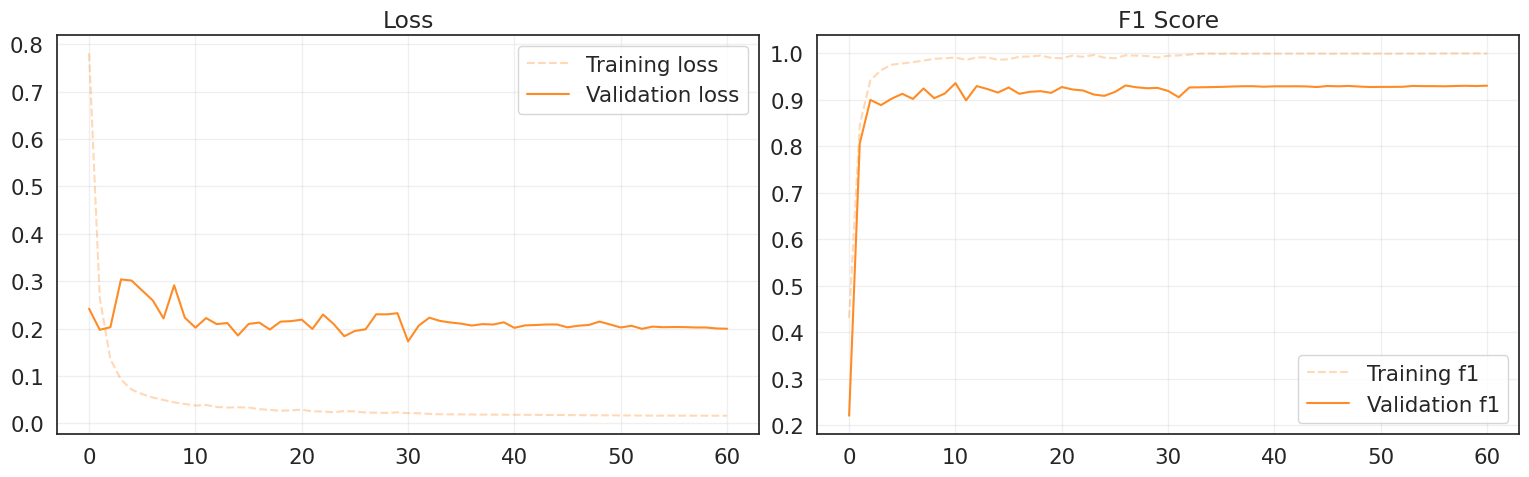

In [43]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9367
Precision over the validation set: 0.9391
Recall over the validation set: 0.9367
F1 score over the validation set: 0.9360


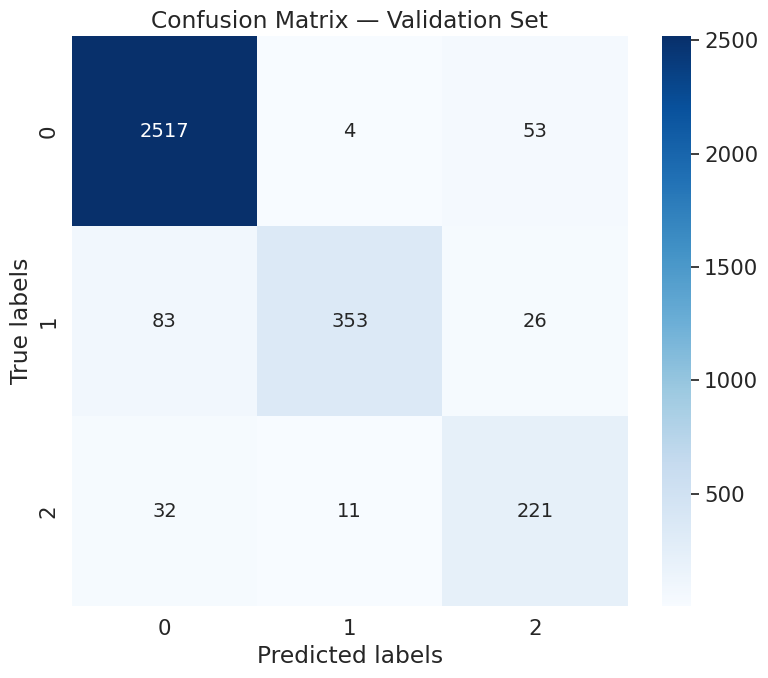

In [44]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb_dyn, xb_static, yb in val_loader:
        xb_dyn = xb_dyn.to(device).float()  # Explicitly cast to float32
        xb_static = xb_static.to(device).float()

        # Forward pass: get model predictions
        logits = model(xb_dyn, xb_static)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

## 🍇 **Using the best model to classify the test dataset, probably can be handled better (run)**

In [45]:
from google.colab import files
#files.upload()

In [46]:
model_path = f"./models/{EXPERIMENT_NAME}_model.pt"
print(model_path)

./models/CNN_RNN_True_ws32_bs128_stride4_lr0.0003_gamma1.7_model.pt


##### Run all of this

In [47]:
if MODEL_ARCHITECTURE == 'CNN':
    model = CNNClassifier(
        input_size=sequence_input_shape[-1],
        sequence_length=WINDOW_SIZE,
        num_classes=num_classes,
        dropout_rate=DROPOUT_RATE,
        num_filters=HIDDEN_SIZE,
        num_cnn_layers=HIDDEN_LAYERS,
        kernel_size=5,
        pool_size=2
    ).to(device)
elif MODEL_ARCHITECTURE == 'RNN':
    model = RecurrentClassifier(
        sequence_input_size=sequence_input_shape[-1],
        static_input_size=static_input_shape[-1],
        hidden_size=HIDDEN_SIZE,
        num_layers=HIDDEN_LAYERS,
        num_classes=num_classes,
        rnn_type=RNN_TYPE,
        bidirectional=RNN_BIDIRECTIONAL,
        dropout_rate=DROPOUT_RATE
    ).to(device)
elif MODEL_ARCHITECTURE == 'CNN_RNN':
    model = CNN_RNN_Attention_Classifier(
        cnn_input_size=sequence_input_shape[-1],
        sequence_length=WINDOW_SIZE,
        static_input_size=static_input_shape[-1],
        num_classes=num_classes,
        cnn_num_filters=CNN_RNN_CNN_FILTERS,
        cnn_kernel_size=CNN_RNN_CNN_KERNEL_SIZE,
        cnn_num_layers=CNN_RNN_CNN_LAYERS,
        cnn_pool_size=CNN_RNN_CNN_POOL_SIZE,
        rnn_hidden_size=CNN_RNN_RNN_HIDDEN_SIZE,
        num_rnn_layers=CNN_RNN_RNN_LAYERS, # Corrected parameter name
        rnn_type=RNN_TYPE,
        rnn_bidirectional=RNN_BIDIRECTIONAL,
        dropout_rate=DROPOUT_RATE
    ).to(device)
else:
    raise ValueError("Invalid MODEL_ARCHITECTURE specified.")

model.load_state_dict(torch.load(model_path))
print("Best performing model in the word with absolutely no overfitting loaded successfully.")

Best performing model in the word with absolutely no overfitting loaded successfully.


In [48]:
all_test_predictions = []
model.eval() # Ensure model is in evaluation mode
with torch.no_grad():
    for xb_dyn, xb_static, yb in test_loader:
        xb_dyn = xb_dyn.to(device).float()
        xb_static = xb_static.to(device).float()
        logits = model(xb_dyn, xb_static)
        predictions = logits.argmax(dim=1).cpu().numpy()
        all_test_predictions.append(predictions)

# Concatenate all predictions
all_test_predictions = np.concatenate(all_test_predictions)

print(f"Generated {len(all_test_predictions)} predictions for the test set.")

Generated 43692 predictions for the test set.


In [49]:
label_inverse_mapping = {v: k for k, v in label_mapping.items()}

# Create a DataFrame to store test predictions along with their original sample_index
test_pred_df = pd.DataFrame({
    'sample_index_sequence': range(len(all_test_predictions)), # Create a unique ID for each sequence
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
test_pred_df['predicted_label_str'] = test_pred_df['predicted_label_int'].map(label_inverse_mapping)

print(test_pred_df.head())


   sample_index_sequence  predicted_label_int predicted_label_str
0                      0                    0             no_pain
1                      1                    0             no_pain
2                      2                    0             no_pain
3                      3                    0             no_pain
4                      4                    0             no_pain


In [50]:
def get_sample_indices_for_sequences(df, window, stride):
    sample_indices = []
    for uid in df['sample_index'].unique():
        user_df = df[df['sample_index'] == uid]
        num_timesteps = len(user_df)

        # Calculate number of sequences generated for this user, similar to build_sequences
        # Need to consider padding that was applied in build_sequences
        padding_len = (window - (num_timesteps % window)) % window
        padded_num_timesteps = num_timesteps + padding_len

        idx = 0
        while idx + window <= padded_num_timesteps:
            sample_indices.append(uid)
            idx += stride
    return np.array(sample_indices)

# Get the original sample_index for each sequence generated for X_test
test_seq_original_sample_indices = get_sample_indices_for_sequences(df_test, WINDOW_SIZE, STRIDE)

# Verify that the number of original sample indices matches the number of predictions
assert len(test_seq_original_sample_indices) == len(all_test_predictions), \
    "Mismatch between number of sequences and number of predictions."

# Create a DataFrame that maps predictions to their original sample_index
predictions_with_original_index_df = pd.DataFrame({
    'sample_index': test_seq_original_sample_indices,
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
predictions_with_original_index_df['predicted_label_str'] = predictions_with_original_index_df['predicted_label_int'].map(label_inverse_mapping)

print("Predictions mapped to original sample indices:")
print(predictions_with_original_index_df.head())
print("\nDataFrame Info:")
predictions_with_original_index_df.info()

Predictions mapped to original sample indices:
   sample_index  predicted_label_int predicted_label_str
0             0                    0             no_pain
1             0                    0             no_pain
2             0                    0             no_pain
3             0                    0             no_pain
4             0                    0             no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43692 entries, 0 to 43691
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   sample_index         43692 non-null  int64 
 1   predicted_label_int  43692 non-null  int64 
 2   predicted_label_str  43692 non-null  object
dtypes: int64(2), object(1)
memory usage: 1.0+ MB


In [51]:
def get_sample_indices_for_sequences(df, window, stride):
    sample_indices = []
    # Feature columns are needed only to determine the number of original timesteps per user
    feature_columns = [col for col in df.columns if col.startswith('pain_survey_')] + \
                      [col for col in df.columns if col.startswith('joint_')] + \
                      ['has_any_disability']

    for uid in df['sample_index'].unique():
        user_df = df[df['sample_index'] == uid]
        num_timesteps = len(user_df) # This is the effective length of `temp` before padding in build_sequences

        # Calculate padding length consistent with build_sequences logic
        padding_len = (window - (num_timesteps % window)) % window

        # Total length of the series after conceptual padding
        total_len_after_padding = num_timesteps + padding_len

        idx = 0
        while idx + window <= total_len_after_padding:
            sample_indices.append(uid)
            idx += stride
    return np.array(sample_indices)

# Corrected window and stride based on the actual number of sequences generated for X_test
# (1300 sequences for 100 users with 160 timesteps each implies 13 sequences/user)
# For 160 timesteps, window=40, stride=10 produces (160 - 40) / 10 + 1 = 13 sequences.
window_for_test_seq_gen = WINDOW_SIZE # Use the global WINDOW_SIZE (80)
stride_for_test_seq_gen = STRIDE # Use the global STRIDE (20)

# Get the original sample_index for each sequence generated for X_test
test_seq_original_sample_indices = get_sample_indices_for_sequences(df_test, window_for_test_seq_gen, stride_for_test_seq_gen)

# Verify that the number of original sample indices matches the number of predictions
assert len(test_seq_original_sample_indices) == len(all_test_predictions), \
    "Mismatch between number of sequences and number of predictions."

# Create a DataFrame that maps predictions to their original sample_index
predictions_with_original_index_df = pd.DataFrame({
    'sample_index': test_seq_original_sample_indices,
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
predictions_with_original_index_df['predicted_label_str'] = predictions_with_original_index_df['predicted_label_int'].map(label_inverse_mapping)

print("Predictions mapped to original sample indices:")
print(predictions_with_original_index_df.head())
print("\nDataFrame Info:")
predictions_with_original_index_df.info()

Predictions mapped to original sample indices:
   sample_index  predicted_label_int predicted_label_str
0             0                    0             no_pain
1             0                    0             no_pain
2             0                    0             no_pain
3             0                    0             no_pain
4             0                    0             no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43692 entries, 0 to 43691
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   sample_index         43692 non-null  int64 
 1   predicted_label_int  43692 non-null  int64 
 2   predicted_label_str  43692 non-null  object
dtypes: int64(2), object(1)
memory usage: 1.0+ MB


In [52]:
final_predictions = predictions_with_original_index_df.groupby('sample_index')['predicted_label_str'].agg(lambda x: x.mode()[0]).reset_index()

# Rename the columns to match the submission format
final_predictions.columns = ['sample_index', 'label']

# Format sample_index to have 3 digits, padded with leading zeros
final_predictions['sample_index'] = final_predictions['sample_index'].astype(str).str.zfill(3)


print("Final predictions grouped by sample_index:")
print(final_predictions.head())
print("\nDataFrame Info:")
final_predictions.info()

Final predictions grouped by sample_index:
  sample_index    label
0          000  no_pain
1          001  no_pain
2          002  no_pain
3          003  no_pain
4          004  no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   sample_index  1324 non-null   object
 1   label         1324 non-null   object
dtypes: object(2)
memory usage: 20.8+ KB


In [53]:
final_predictions.to_csv(f'submission_{EXPERIMENT_NAME}.csv', index=False)
print(f"submission_{EXPERIMENT_NAME}.csv created successfully.")

submission_CNN_RNN_True_ws32_bs128_stride4_lr0.0003_gamma1.7.csv created successfully.


## ❌ **Let's do some hyprland tuning (be carefull still need to be cleaned)**

In [62]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold
import torch.optim as optim


N_SPLITS = 5

df_full_train = pd.concat([df_train, df_val], ignore_index=True)

In [63]:

LABEL_COLUMN = 'label'
GROUP_COLUMN = 'sample_index'


X_kfold = df_full_train.index
y_kfold = df_full_train[LABEL_COLUMN]
groups_kfold = df_full_train[GROUP_COLUMN]

skf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

kfold_iterator = skf.split(X_kfold, y_kfold, groups_kfold)

In [65]:
for fold, (train_indices, val_indices) in enumerate(kfold_iterator):

    print(f"--- FOLD {fold + 1}/{N_SPLITS} ---")

    fold_df_train = df_full_train.iloc[train_indices].copy()
    fold_df_val = df_full_train.iloc[val_indices].copy()

    fold_df_test = df_test.copy()

    scale_columns = [col for col in fold_df_train.columns if col.startswith('joint_')]
    scaler = StandardScaler()

    scaler.fit(fold_df_train[scale_columns])

    fold_df_train[scale_columns] = scaler.transform(fold_df_train[scale_columns])
    fold_df_val[scale_columns] = scaler.transform(fold_df_val[scale_columns])
    fold_df_test[scale_columns] = scaler.transform(fold_df_test[scale_columns])
    print(f"Fold {fold+1}: Data normalized.")

    train_transforms = [Jitter(sigma=0.01)]
    val_transforms = []

    X_train_dynamic, X_train_static, y_train = build_sequences(
        fold_df_train, WINDOW_SIZE, STRIDE, LABEL_COLUMN, PAIN_SURVEY_COLUMNS
    )
    X_val_dynamic, X_val_static, y_val = build_sequences(
        fold_df_val, WINDOW_SIZE, STRIDE, LABEL_COLUMN, PAIN_SURVEY_COLUMNS
    )

    X_test_dynamic, X_test_static, y_test = build_sequences(
        fold_df_test, WINDOW_SIZE, STRIDE, LABEL_COLUMN, PAIN_SURVEY_COLUMNS, is_test=True
    )

    train_dataset = TimeSeriesDataset(X_train_dynamic, X_train_static, y_train, transforms=train_transforms)
    val_dataset = TimeSeriesDataset(X_val_dynamic, X_val_static, y_val, transforms=val_transforms)
    test_dataset = TimeSeriesDataset(X_test_dynamic, X_test_static, y_test, transforms=val_transforms)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE * 2, shuffle=False, pin_memory=True, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE * 2, shuffle=False, pin_memory=True, num_workers=2)

    input_shape = (X_train_dynamic.shape[1], X_train_dynamic.shape[2])
    static_shape = (X_train_static.shape[1],)
    N_CLASSES = len(np.unique(y_kfold))

    model = CNN_RNN_Attention_Classifier(
        cnn_input_size=input_shape[1],
        sequence_length=input_shape[0],
        static_input_size=static_shape[0],
        num_classes=N_CLASSES,
        cnn_num_filters=CNN_RNN_CNN_FILTERS,
        cnn_kernel_size=CNN_RNN_CNN_KERNEL_SIZE,
        cnn_pool_size=CNN_RNN_CNN_POOL_SIZE,
        cnn_num_layers=CNN_RNN_CNN_LAYERS,
        rnn_hidden_size=CNN_RNN_RNN_HIDDEN_SIZE,
        num_rnn_layers=CNN_RNN_RNN_LAYERS,
        rnn_type=RNN_TYPE,
        rnn_bidirectional=RNN_BIDIRECTIONAL,
        dropout_rate=DROPOUT_RATE
    ).to(device)

    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)
    loss_fn = FocalLoss(gamma=GAMMA).to(device)
    grad_scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.2, patience=20, min_lr=1e-6
    )

    best_model_path_fold = f'best_model_fold_{fold+1}.pth'
    early_stopping = EarlyStopping(
        patience=PATIENCE,
        verbose=False,
        delta=1e-4,
        path=best_model_path_fold,
        trace_func=print,
        metric_to_monitor='val_f1'
    )

    print(f"Fold {fold+1}: Start training...")
    for epoch in range(EPOCHS):
        train_loss, train_f1, _ = train_loop(
            model, train_loader, loss_fn, optimizer, grad_scaler, device
        )

        val_loss, val_f1, _, _ = val_loop(
            model, val_loader, loss_fn, device
        )

        scheduler.step(val_f1)
        early_stopping(val_f1, model)

        if early_stopping.early_stop:
            print(f"Fold {fold+1}: Early stopping epoch {epoch+1}")
            break

    # Salva il punteggio migliore di questo fold
    best_f1_score = early_stopping.best_score
    all_fold_scores.append(best_f1_score)
    print(f"Fold {fold+1}: Training completed. Best Val F1 = {best_f1_score:.4f}")

    model.load_state_dict(torch.load(best_model_path_fold))
    model.eval()

    fold_test_logits = []
    with torch.no_grad():
        for dynamic_batch, static_batch, _ in test_loader:
            dynamic_batch, static_batch = dynamic_batch.to(device), static_batch.to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                outputs = model(dynamic_batch, static_batch)

            fold_test_logits.append(outputs.cpu().numpy())

    test_predictions = np.concatenate(fold_test_logits)
    test_predictions_list.append(test_predictions)
    print(f"Fold {fold+1}: Predictions on test set completed.")

print("--- K-FOLD CROSS-VALIDATION COMPLETATA ---")

mean_cv_f1 = np.mean(all_fold_scores)
std_cv_f1 = np.std(all_fold_scores)

print(f"\n--- Results Cross-Validation ---")
print(f"Scores F1 individual: {[round(f, 4) for f in all_fold_scores]}")
print(f"F1 mean (CV): {mean_cv_f1:.4f} +/- {std_cv_f1:.4f}")



avg_test_logits = np.mean(test_predictions_list, axis=0)

final_test_probs = torch.softmax(torch.tensor(avg_test_logits), dim=1)

final_test_preds = torch.argmax(final_test_probs, dim=1).numpy()

print(f"\nPredizioni finali (ensemble) create. Shape: {final_test_preds.shape}")
print("Ora puoi usare 'final_test_preds' per creare il tuo file di sottomissione.")

# Esempio per creare il submission DataFrame
submission_df = pd.DataFrame({'id': df_test['id'].unique(), 'pain': final_test_preds})
submission_df.to_csv('submission_ensemble_cv.csv', index=False)

--- FOLD 1/5 ---
Fold 1: Data normalized.


NameError: name 'EarlyStopping' is not defined

In [ ]:
def k_shuffle_split_cross_validation_round_cnn(df, epochs, criterion, device,
                            k, n_val_users, n_test_users, batch_size, hidden_layers, hidden_size, learning_rate, dropout_rate,
                            window_size, stride, architecture_type, # Changed rnn_type to architecture_type
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name="",
                            lr_scheduler_patience=20, lr_scheduler_factor=0.1, gamma=1.5):
    """
    Perform K-fold shuffle split cross-validation with user-based splitting for time series data.

    Args:
        df: DataFrame with columns ['sample_index', 'label', 'pain_survey_X', 'joint_XX', 'has_any_disability']
        epochs: Number of training epochs
        criterion: Loss function (will be replaced by FocalLoss within the function)
        device: torch.device for computation
        k: Number of cross-validation splits
        n_val_users: Number of users for validation set
        n_test_users: Number of users for test set
        batch_size: Batch size for training
        hidden_layers: Number of CNN layers
        hidden_size: Number of filters per layer
        learning_rate: Learning rate for optimizer
        dropout_rate: Dropout rate
        window_size: Length of sliding windows
        stride: Step size for sliding windows
        architecture_type: Type of architecture ('CNN')
        l1_lambda: L1 regularization coefficient (if used)
        l2_lambda: L2 regularization coefficient (weight_decay)
        patience: Early stopping patience
        evaluation_metric: Metric to monitor for early stopping
        mode: 'max' or 'min' for evaluation metric
        restore_best_weights: Whether to restore best weights after training
        writer: TensorBoard writer
        verbose: Verbosity level
        seed: Random seed
        experiment_name: Name for experiment logging
        lr_scheduler_patience (int): Number of epochs with no improvement after which learning rate will be reduced.
        lr_scheduler_factor (float): Factor by which the learning rate will be reduced.
        gamma (float): Gamma parameter for FocalLoss.

    Returns:
        fold_losses: Dict with validation losses for each split
        fold_metrics: Dict with validation F1 scores for each split
        best_scores: Dict with best F1 score for each split plus mean and std
    """

    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}

    # Get model architecture parameters
    # Use global input_shape and num_classes derived from the initial data processing
    in_features = input_shape[-1] # From X_train.shape[1:] computed earlier
    num_classes_model = num_classes # From num_classes computed earlier

    # Initialise model architecture
    model = CNNClassifier(
        input_size=in_features,
        sequence_length=window_size,
        num_classes=num_classes_model,
        dropout_rate=dropout_rate,
        num_filters=hidden_size,
        num_cnn_layers=hidden_layers,
        kernel_size=5,
        pool_size=2
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())

    # Extract user labels from the original df for stratification
    # Ensure original string labels are used before integer mapping for stratification
    user_labels_full = df[['sample_index', 'label']].drop_duplicates().set_index('sample_index')['label']

    # Iterate through K random splits
    for split_idx in range(k):

        if verbose > 0:
            print(f"Split {split_idx+1}/{k}")

        # Get unique user IDs
        unique_users = df['sample_index'].unique()

        # Create a stratify_labels array corresponding to unique_users
        stratify_labels_for_users = user_labels_full.loc[unique_users].values

        # First split: Separate out test_users (CV test set) from the rest (temp_train_val_users)
        # Use N_TEST_USERS for the test set and stratify
        temp_train_val_users, test_users = train_test_split(
            unique_users,
            test_size=n_test_users,
            stratify=stratify_labels_for_users,
            random_state=seed + split_idx
        )

        # Create stratify_labels for the temp_train_val_users
        stratify_labels_for_temp = user_labels_full.loc[temp_train_val_users].values

        # Second split: Separate temp_train_val_users into train_users and val_users
        # Use N_VAL_USERS for the validation set and stratify
        train_users, val_users = train_test_split(
            temp_train_val_users,
            test_size=n_val_users,
            stratify=stratify_labels_for_temp,
            random_state=seed + split_idx
        )

        # Split the dataset into training, validation, and test sets based on user IDs
        df_train = df[df['sample_index'].isin(train_users)].copy()
        df_val = df[df['sample_index'].isin(val_users)].copy()
        # For cross-validation, df_test_cv needs to be from the train_df to have labels for evaluation
        df_test_cv = df[df['sample_index'].isin(test_users)].copy()

        # Define a mapping of activity names to integer labels - using the global label_mapping
        df_train['label'] = df_train['label'].map(label_mapping)
        df_val['label'] = df_val['label'].map(label_mapping)
        if not df_test_cv.empty:
            df_test_cv['label'] = df_test_cv['label'].map(label_mapping)

        # Define the columns to be normalised - these are the 'joint_' columns
        joint_columns = [col for col in df_train.columns if col.startswith('joint_')]

        # Calculate the minimum and maximum values from the training data only
        mins = df_train[joint_columns].min()
        maxs = df_train[joint_columns].max()

        # Apply normalisation to the specified columns in all datasets
        for column in joint_columns:
            col_min = mins[column]
            col_max = maxs[column]

            # Check for constant columns to prevent division by zero
            if col_max == col_min:
                if verbose > 0:
                    print(f"  Warning: Column '{column}' has constant values in df_train. Setting to 0 after 'normalization'.")
                df_train[column] = 0.0
                df_val[column] = 0.0
                df_test_cv[column] = 0.0
            else:
                df_train[column] = (df_train[column] - col_min) / (col_max - col_min)
                df_val[column] = (df_val[column] - col_min) / (col_max - col_min)
                df_test_cv[column] = (df_test_cv[column] - col_min) / (col_max - col_min)

        # First, fill any NaN values that might have been introduced unexpectedly.
        df_train.fillna(0, inplace=True);
        df_val.fillna(0, inplace=True);
        df_test_cv.fillna(0, inplace=True);
        # Replace inf values which might result from 0/0 operations if not caught by the constant column check
        df_train.replace([np.inf, -np.inf], 0, inplace=True);
        df_val.replace([np.inf, -np.inf], 0, inplace=True);
        df_test_cv.replace([np.inf, -np.inf], 0, inplace=True);


        # Build sequences using the existing build_sequences function
        X_train, y_train_sequences = build_sequences(df_train, window=window_size, stride=stride)
        X_val, y_val = build_sequences(df_val, window=window_size, stride=stride)
        X_test, y_test = build_sequences(df_test_cv, window=window_size, stride=stride)

        # Convert any remaining NaNs or Infs to finite numbers
        X_train = np.nan_to_num(X_train)
        X_val = np.nan_to_num(X_val)
        X_test = np.nan_to_num(X_test)

        if verbose > 0:
            print(f"  Training sequences shape: {X_train.shape}")
            print(f"  Validation sequences shape: {X_val.shape}")
            print(f"  CV Test sequences shape: {X_test.shape}")

        # Create PyTorch datasets, explicitly casting to .float()
        train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train_sequences))
        val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))
        test_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))

        # Calculate class weights for handling imbalanced datasets FOR THIS FOLD
        class_counts_fold = np.bincount(y_train_sequences)
        class_weights_fold = 1.0 / (class_counts_fold + 1e-5)
        class_weights_fold = class_weights_fold / class_weights_fold.sum() * num_classes_model
        class_weights_fold = torch.tensor(class_weights_fold, dtype=torch.float32).to(device)
        if verbose > 0:
            print("  Calculated Fold Class Weights (for FocalLoss alpha):", class_weights_fold)

        # --- Start of weighted sampling logic ---
        weights_vector_fold = []

        # Get user-level information from the current df_train, retaining original string labels
        user_level_info_df_raw_labels = df[['sample_index', 'has_any_disability', 'label']].drop_duplicates(subset=['sample_index']).set_index('sample_index')
        user_level_info_df_raw_labels = user_level_info_df_raw_labels[user_level_info_df_raw_labels.index.isin(df_train['sample_index'].unique())]

        # Calculate weights for 'pirate' and 'no_pirate' users in this fold using ORIGINAL STRING LABELS
        pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 1]
        pirate_label_counts_fold = pirate_users_info_fold['label'].value_counts()
        total_pirate_users_fold = pirate_label_counts_fold.sum()
        weights_pirate_fold = {
            label: (1.0 / count) * (total_pirate_users_fold / len(pirate_label_counts_fold))
            for label, count in pirate_label_counts_fold.items()
        } if len(pirate_label_counts_fold) > 0 else {} # Handle case where no pirate users in fold
        if sum(weights_pirate_fold.values()) > 0:
            sum_weights_pirate_fold = sum(weights_pirate_fold.values())
            weights_pirate_fold = {label: weight / sum_weights_pirate_fold for label, weight in weights_pirate_fold.items()}


        no_pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 0]
        no_pirate_label_counts_fold = no_pirate_users_info_fold['label'].value_counts()
        total_no_pirate_users_fold = no_pirate_label_counts_fold.sum()
        weights_no_pirate_fold = {
            label: (1.0 / count) * (total_no_pirate_users_fold / len(no_pirate_label_counts_fold))
            for label, count in no_pirate_label_counts_fold.items()
        } if len(no_pirate_label_counts_fold) > 0 else {} # Handle case where no non-pirate users in fold
        if sum(weights_no_pirate_fold.values()) > 0:
            sum_weights_no_pirate_fold = sum(weights_no_pirate_fold.values())
            weights_no_pirate_fold = {label: weight / sum_weights_no_pirate_fold for label, weight in weights_no_pirate_fold.items()}


        # Reconstruct the mapping from sequence index in train_ds to its original sample_index (user_id)
        original_sample_indices_for_train_sequences_fold = []
        for user_id in df_train['sample_index'].unique():
            user_data_len = len(df_train[df_train['sample_index'] == user_id])
            padding_len = (window_size - (user_data_len % window_size)) % window_size
            total_len_after_padding = user_data_len + padding_len

            idx = 0
            while idx + window_size <= total_len_after_padding:
                original_sample_indices_for_train_sequences_fold.append(user_id)
                idx += stride

        if len(original_sample_indices_for_train_sequences_fold) != len(train_ds):
            # This error check is critical. If it fails, something is wrong with sequence generation consistency.
            raise ValueError(
                f"Mismatch in number of sequences for weight calculation and actual train_ds length for split {split_idx}.\n"
                f"Expected {len(train_ds)} sequences, but got {len(original_sample_indices_for_train_sequences_fold)}."
                "This indicates an inconsistency in how sequences are generated or accounted for."
            )

        for sequence_original_sample_index in original_sample_indices_for_train_sequences_fold:
            has_disability = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'has_any_disability']
            # Retrieve the original string label directly
            original_string_label = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'label']

            if has_disability:
                # Use .get with a default value (e.g., 1.0) to prevent KeyError if a label is missing from weights_pirate_fold
                weight = weights_pirate_fold.get(original_string_label, 1.0)
            else:
                weight = weights_no_pirate_fold.get(original_string_label, 1.0)

            weights_vector_fold.append(weight)

        weights_vector_fold = torch.tensor(weights_vector_fold, dtype=torch.float32)

        weighted_sampler_fold = WeightedRandomSampler(weights=weights_vector_fold, num_samples=len(train_ds), replacement=True)

        # --- End of weighted sampling logic ---

        # Create data loaders, passing the weighted_sampler_fold to train_loader
        # shuffle=False when using a sampler
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=False, drop_last=False, sampler=weighted_sampler_fold)
        val_loader   = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)
        test_loader  = make_loader(test_ds, batch_size=batch_size, shuffle=False, drop_last=False)

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Create directory for model checkpoints
        os.makedirs(f"models/{experiment_name}", exist_ok=True)

        # Re-initialize criterion with fold-specific class weights and FocalLoss
        criterion_per_fold = FocalLoss(alpha=class_weights_fold, gamma=gamma, reduction='mean') # Use gamma parameter here

        # Initialize ReduceLROnPlateau scheduler for this fold
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode=mode,
            factor=lr_scheduler_factor,
            patience=lr_scheduler_patience,
            min_lr=1e-7 # Define a minimum learning rate
        )

        # Train model on current split
        model, training_history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion_per_fold, # Use fold-specific criterion
            optimizer=optimizer,
            scaler=split_scaler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=restore_best_weights,
            experiment_name=experiment_name+"/split_"+str(split_idx),
            scheduler=scheduler # Pass the scheduler to the fit function
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print(f"Best score: {best_scores['mean']:.4f}\u00B1{best_scores['std']:.4f}")

    return fold_losses, fold_metrics, best_scores


def grid_search_cv_cnn(df, param_grid, fixed_params, cv_params, verbose=True):
    """
    Execute grid search with K-shuffle-split cross-validation for CNN models on time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        param_grid: Dict of parameters to test, e.g. {'batch_size': [16, 32], 'cnn_type': ['CNN']}
        fixed_params: Dict of fixed hyperparameters (num_filters, learning_rate, window_size, stride, etc.)
        cv_params: Dict of CV settings (epochs, k, patience, criterion, scaler, device, etc.)
        verbose: Print progress for each configuration

    Returns:
        results: Dict with scores for each configuration
        best_config: Dict with best hyperparameter combination
        best_score: Best mean F1 score achieved
    """
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    combinations = list(product(*param_values))

    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = "_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Execute cross-validation
        _, _, fold_scores = k_shuffle_split_cross_validation_round_cnn(
            df=df,
            experiment_name=config_str,
            **run_params,
            **cv_params
        )

        # Store results
        results[config_str] = fold_scores

        # Track best configuration
        if fold_scores["mean"] > best_score:
            best_score = fold_scores["mean"]
            best_config = current_config.copy()
            if verbose:
                print("  NEW BEST SCORE!")

        if verbose:
            print(f"  F1 Score: {fold_scores['mean']:.4f}\u00B1{fold_scores['std']:.4f}")

    return results, best_config, best_score


def plot_top_configurations_cnn(results, k_splits, top_n=5, figsize=(14, 7)):
    """
    Visualise top N CNN configurations with boxplots of F1 scores across CV splits.

    Args:
        results: Dict of results from grid_search_cv_cnn
        k_splits: Number of CV splits used
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    # Sort by mean score
    config_scores = {name: data['mean'] for name, data in results.items()}
    sorted_configs = sorted(config_scores.items(), key=lambda x: x[1], reverse=True)

    # Select top N
    top_configs = sorted_configs[:min(top_n, len(sorted_configs))]

    # Prepare boxplot data
    boxplot_data = []
    labels = []

    # Define a dictionary for replacements, ordered to handle prefixes correctly
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nCL=', # Changed from HL to CL for CNN Layers
        'hidden_size_': '\nNF=', # Changed from HS to NF for Num Filters
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'architecture_type_': '\nARCH=', # Changed from rnn_type to architecture_type
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2=',
        'gamma_': '\nGAMMA='
    }

    # Replacements for separators
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nCL=',
        '_hidden_size_': '\nNF=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_architecture_type_': '\nARCH=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_gamma_': '\nGAMMA=',
        '_': ''
    }

    for config_name, mean_score in top_configs:
        # Extract best score from each split (auto-detect number of splits)
        split_scores = []
        for i in range(k_splits):
            if f'split_{i}' in results[config_name]:
                split_scores.append(results[config_name][f'split_{i}']) # Access the first element if it's a list
        boxplot_data.append(split_scores)

        # Verify we have the expected number of splits
        if len(split_scores) != k_splits:
            print(f"Warning: Config {config_name} has {len(split_scores)} splits, expected {k_splits}")

        # Create readable label using the replacements dictionary
        readable_label = config_name
        for old, new in replacements.items():
            readable_label = readable_label.replace(old, new)

        # Apply separator replacements
        for old, new in separator_replacements.items():
             readable_label = readable_label.replace(old, new)

        labels.append(f"{readable_label}\n(\u03BC={mean_score:.3f})")

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    bp = ax.boxplot(boxplot_data, labels=labels, patch_artist=True,
                    showmeans=True, meanline=True)

    # Styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)

    # Highlight best configuration
    if labels:
        ax.get_xticklabels()[0].set_fontweight('bold')

    ax.set_ylabel('F1 Score')
    ax.set_xlabel('Configuration')
    ax.set_title(f'Top {len(top_configs)} CNN Configurations - F1 Score Distribution Across {k_splits} Splits')
    ax.grid(alpha=0.3, axis='y')

    plt.xticks(rotation=0, ha='center')
    plt.tight_layout()
    plt.show()

In [ ]:
K=2 # Setting K to 2 to have enough splits for mean/std. It was 1 previously.
# Define parameters to search
param_grid = {
    'window_size': [40],
    'stride': [4, 8],
    'batch_size': [128],
    'dropout_rate': [0.2],
    'hidden_layers': [2], # Expanded range for hidden layers
    'hidden_size': [256], # Expanded range for hidden size
    'l1_lambda': [0.000],
    'l2_lambda': [0.000],
    'gamma': [0.5, 1.0, 1.5, 2.0, 2.5, 3.0], # Expanded range for gamma
}

# Fixed hyperparameters (not being tuned)
fixed_params = {
    'architecture_type': 'CNN',
    'learning_rate': 1e-3,
}

# Cross-validation settings
cv_params = {
    'epochs': EPOCHS,
    'criterion': CRITERION, # This will be ignored as FocalLoss is initiated inside k_shuffle_split_cross_validation_round_cnn
    'device': device,
    'k': K,
    'n_val_users': 60, # Using N_VAL_USERS global variable
    'n_test_users': 60,
    'patience': PATIENCE,
    'verbose': 0,
    'seed': SEED,
    'lr_scheduler_patience': 20,
    'lr_scheduler_factor': 0.2,
}

# Execute search
results, best_config, best_score = grid_search_cv_cnn(
    df=df,
    param_grid=param_grid,
    fixed_params=fixed_params,
    cv_params=cv_params
)
